# **Complex Engineering Problem (CEP): Autonomous Vacuum Robot — Hybrid Search & CSP Task Scheduler**

### **Group Members**
| Roll Number | Student Name |
| :--- | :--- |
| **CS-24023** | **SYED RAMISH AKHTER** |
| **CS-24025** | **SYED ARSHMAN ALI SHAH** |
| **CS-24026** | **MAIR NASIR** |
| **CS-24034** | **SIRAJ-UL-HAQ** |

**Submission Date:** November 22, 2026

---

# **Phase 1: Environment & Schedule File Parsing & Grid Representation**

Parses `Environment.txt` and `Schedule.txt` into structured dictionaries and constructs the 2D occupancy grid (`0` = free cell, `1` = obstacle `#`), mapping the charging station `C` and dirty target cells `D1..D6`. Explicit coordinate and constraint validation ensures malformed inputs are caught before search or scheduling begins.

In [1]:
import re
import os
import math
import time
import heapq
import copy
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def parse_int_tuples(line):
    matches = re.findall(r'\((\d+)\s*,\s*(\d+)\)', line)
    return [(int(r), int(c)) for r, c in matches]

def parse_str_tuples(line):
    matches = re.findall(r'\((\w+)\s*,\s*(\w+)\)', line)
    return matches[0] if matches else None

def load_environment(filename):
    with open(filename, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    rows, cols = map(int, lines[0].split(','))
    num_obstacles = int(lines[1])
    obstacles = set(parse_int_tuples(lines[2]))
    num_dirty = int(lines[3])
    dirty_list = parse_int_tuples(lines[4])
    charging_station = parse_int_tuples(lines[5])[0]
    
    dirty_map = {f"D{i+1}": coord for i, coord in enumerate(dirty_list)}
    return {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_list": dirty_list,
        "dirty_map": dirty_map,
        "charging_station": charging_station
    }

def load_schedule(filename):
    with open(filename, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    num_slots = int(lines[0])
    num_prec = int(lines[1])
    precedence = []
    idx = 2
    for _ in range(num_prec):
        precedence.append(parse_str_tuples(lines[idx]))
        idx += 1
    num_latest = int(lines[idx])
    idx += 1
    latest_slot = []
    for _ in range(num_latest):
        latest_slot.append(parse_str_tuples(lines[idx]))
        idx += 1
    return {
        "num_slots": num_slots,
        "precedence": precedence,
        "latest_slot": latest_slot
    }

def display_environment_grid(env):
    """Builds and displays a visual 2D grid table of the parsed environment."""
    rows, cols = env["rows"], env["cols"]
    grid_matrix = np.full((rows, cols), ".", dtype=object)
    
    for r, c in env["obstacles"]:
        grid_matrix[r, c] = "#"
        
    cs_r, cs_c = env["charging_station"]
    grid_matrix[cs_r, cs_c] = "C"
    
    for task, (dr, dc) in env["dirty_map"].items():
        grid_matrix[dr, dc] = task
        
    df_grid = pd.DataFrame(
        grid_matrix,
        index=[f"R{r}" for r in range(rows)],
        columns=[f"C{c}" for c in range(cols)]
    )
    print("\n--- Visual 12x12 Environment Map (C = Base, # = Obstacle, D1-D6 = Dirt) ---")
    display(df_grid)

# --- Execute Phase 1 Parsing & Grid Display ---
env_data = load_environment("Environment.txt")
print("--- Environment Data ---")
for key, value in env_data.items():
    print(f"{key}: {value}")

print("\n--- Schedule Data ---")
schedule_data = load_schedule("Schedule.txt")
for key, value in schedule_data.items():
    print(f"{key}: {value}")

display_environment_grid(env_data)

--- Environment Data ---
rows: 12
cols: 12
obstacles: {(4, 9), (5, 4), (9, 2), (2, 2), (10, 9), (1, 6), (7, 7), (4, 2), (3, 9), (5, 3), (8, 2), (9, 7), (10, 2), (2, 4), (10, 5), (10, 8), (7, 9), (6, 10), (3, 2), (5, 2), (8, 7), (10, 7), (2, 3), (2, 9), (7, 8)}
dirty_list: [(3, 3), (9, 8), (2, 10), (9, 3), (0, 11), (11, 0)]
dirty_map: {'D1': (3, 3), 'D2': (9, 8), 'D3': (2, 10), 'D4': (9, 3), 'D5': (0, 11), 'D6': (11, 0)}
charging_station: (0, 0)

--- Schedule Data ---
num_slots: 7
precedence: [('D1', 'D3'), ('D4', 'D2'), ('D2', 'D5')]
latest_slot: [('D1', 'T3'), ('D4', 'T5')]

--- Visual 12x12 Environment Map (C = Base, # = Obstacle, D1-D6 = Dirt) ---


,C0,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
R0,C,.,.,.,.,.,.,.,.,.,.,D5
R1,.,.,.,.,.,.,#,.,.,.,.,.
R2,.,.,#,#,#,.,.,.,.,#,D3,.
R3,.,.,#,D1,.,.,.,.,.,#,.,.
R4,.,.,#,.,.,.,.,.,.,#,.,.
R5,.,.,#,#,#,.,.,.,.,.,.,.
R6,.,.,.,.,.,.,.,.,.,.,#,.
R7,.,.,.,.,.,.,.,#,#,#,.,.
R8,.,.,#,.,.,.,.,#,.,.,.,.
R9,.,.,#,D4,.,.,.,#,D2,.,.,.


# **Phase 2: Multi-Algorithm Graph Search & Heuristic Ablation**

Implements the Section 5.5 navigation interface (`goal_test`, `get_successors`, `path_cost`, `heuristic`, `search`) across six algorithms: BFS, DFS, GBFS, and A* with Manhattan ($L_1$), Euclidean ($L_2$), and Zero heuristics. For 4-directional unit-cost grid movement, Manhattan distance is both **admissible** and **consistent**, guaranteeing optimal shortest paths while expanding significantly fewer nodes than BFS or Euclidean A* on U-shaped obstacle traps.

In [2]:
import time
import math
import heapq
from collections import deque
import numpy as np

LAST_SEARCH_TELEMETRY = {}


# ==============================================================================
# 1. REQUIRED SECTION 5.5 FUNCTIONS: goal_test, get_successors, path_cost, heuristic
# ==============================================================================
def goal_test(state, goal_state):
    """Checks whether the goal has been reached."""
    return state == goal_state


def get_successors(state, grid):
    """
    Find all valid successor states without including cells outside the grid
    or obstacle cells.

    Arguments:
        state (tuple): Current robot position (row, col).
        grid (2D array/list): Environment representation (0 = free, 1 = obstacle).

    Returns:
        list[tuple]: Valid successors as (next_state, action, step_cost).
    """
    rows, cols = len(grid), len(grid[0])
    r, c = state
    moves = [
        ((-1, 0), "UP"),
        ((1, 0), "DOWN"),
        ((0, -1), "LEFT"),
        ((0, 1), "RIGHT"),
    ]

    successors = []
    for (dr, dc), action in moves:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == 0:
            successors.append(((nr, nc), action, 1))

    return successors


def path_cost(path):
    """
    Calculates the total cost of a path (number of movements = len(path) - 1).
    Handles empty paths and single-state paths appropriately.
    """
    if not path or len(path) <= 1:
        return 0
    return len(path) - 1


def heuristic(state, goal_state):
    """Manhattan distance heuristic for 4-directional grid movement."""
    return abs(state[0] - goal_state[0]) + abs(state[1] - goal_state[1])


def euclidean_heuristic(state, goal_state):
    return math.hypot(state[0] - goal_state[0], state[1] - goal_state[1])


def zero_heuristic(state, goal_state):
    return 0


# ==============================================================================
# 2. UNIFIED SEARCH FUNCTION (EXACT SECTION 5.5 SIGNATURE)
# ==============================================================================
def reconstruct_path(parent, start, goal):
    if goal not in parent and start != goal:
        return []
    path = [goal]
    curr = goal
    while curr != start:
        curr = parent[curr]
        path.append(curr)
    path.reverse()
    return path


def _record_telemetry(grid, algorithm, t0, expanded_order, visited_set):
    visit_counts = np.zeros((len(grid), len(grid[0])), dtype=int)
    for r, c in expanded_order:
        visit_counts[r, c] += 1

    LAST_SEARCH_TELEMETRY.clear()
    LAST_SEARCH_TELEMETRY.update({
        "algorithm": algorithm,
        "time_ms": (time.perf_counter() - t0) * 1000.0,
        "nodes_expanded": len(expanded_order),
        "expanded_order": expanded_order,
        "visited_order": expanded_order,
        "visited": visited_set,
        "visit_counts": visit_counts,
    })


def search(grid, start, goal, algorithm="A*_Manhattan"):
    """
    Implements the selected graph-search algorithm.

    Arguments:
        grid: Environment representation.
        start: Starting position.
        goal: Target position.
        algorithm: Selected graph-search algorithm.

    Returns:
        tuple: (path, cost, nodes_expanded)
    """
    t0 = time.perf_counter()
    expanded_order = []

    if goal_test(start, goal):
        expanded_order.append(start)
        _record_telemetry(grid, algorithm, t0, expanded_order, {start})
        return [start], path_cost([start]), 1

    heuristic_map = {
        "A*_Manhattan": heuristic,
        "GBFS": heuristic,
        "A*_Euclidean": euclidean_heuristic,
        "A*_Zero": zero_heuristic,
    }

    parent = {}

    if algorithm == "BFS":
        frontier = deque([start])
        visited = {start}
        while frontier:
            curr = frontier.popleft()
            expanded_order.append(curr)
            if goal_test(curr, goal):
                p = reconstruct_path(parent, start, goal)
                _record_telemetry(grid, algorithm, t0, expanded_order, visited)
                return p, path_cost(p), len(expanded_order)

            for next_state, action, step_cost in get_successors(curr, grid):
                if next_state not in visited:
                    visited.add(next_state)
                    parent[next_state] = curr
                    frontier.append(next_state)

        _record_telemetry(grid, algorithm, t0, expanded_order, visited)
        return [], float("inf"), len(expanded_order)

    elif algorithm == "DFS":
        stack = [start]
        visited = set()
        while stack:
            curr = stack.pop()
            if curr in visited:
                continue
            visited.add(curr)
            expanded_order.append(curr)
            if goal_test(curr, goal):
                p = reconstruct_path(parent, start, goal)
                _record_telemetry(grid, algorithm, t0, expanded_order, visited)
                return p, path_cost(p), len(expanded_order)

            for next_state, action, step_cost in reversed(get_successors(curr, grid)):
                if next_state not in visited:
                    parent[next_state] = curr
                    stack.append(next_state)

        _record_telemetry(grid, algorithm, t0, expanded_order, visited)
        return [], float("inf"), len(expanded_order)

    elif algorithm == "GBFS":
        h_fn = heuristic_map[algorithm]
        pq = [(h_fn(start, goal), start)]
        visited = {start}
        while pq:
            _, curr = heapq.heappop(pq)
            expanded_order.append(curr)
            if goal_test(curr, goal):
                p = reconstruct_path(parent, start, goal)
                _record_telemetry(grid, algorithm, t0, expanded_order, visited)
                return p, path_cost(p), len(expanded_order)

            for next_state, action, step_cost in get_successors(curr, grid):
                if next_state not in visited:
                    visited.add(next_state)
                    parent[next_state] = curr
                    heapq.heappush(pq, (h_fn(next_state, goal), next_state))

        _record_telemetry(grid, algorithm, t0, expanded_order, visited)
        return [], float("inf"), len(expanded_order)

    elif algorithm in ("A*_Manhattan", "A*_Euclidean", "A*_Zero"):
        h_fn = heuristic_map[algorithm]
        pq = [(h_fn(start, goal), 0, start)]
        best_g = {start: 0}
        while pq:
            _, g_cost, curr = heapq.heappop(pq)
            if g_cost > best_g.get(curr, float("inf")):
                continue
            expanded_order.append(curr)
            if goal_test(curr, goal):
                p = reconstruct_path(parent, start, goal)
                _record_telemetry(grid, algorithm, t0, expanded_order, set(best_g.keys()))
                return p, path_cost(p), len(expanded_order)

            for next_state, action, step_cost in get_successors(curr, grid):
                tentative_g = g_cost + step_cost
                if tentative_g < best_g.get(next_state, float("inf")):
                    best_g[next_state] = tentative_g
                    parent[next_state] = curr
                    f_cost = tentative_g + h_fn(next_state, goal)
                    heapq.heappush(pq, (f_cost, tentative_g, next_state))

        _record_telemetry(grid, algorithm, t0, expanded_order, set(best_g.keys()))
        return [], float("inf"), len(expanded_order)

    else:
        raise ValueError(f"Unsupported algorithm: {algorithm}")


# ==============================================================================
# 3. PHASE 2 BENCHMARK: U-TRAP STRESS TEST
# ==============================================================================
def build_grid(env):
    g = np.zeros((env["rows"], env["cols"]), dtype=int)
    for r, c in env["obstacles"]:
        g[r, c] = 1
    return g

grid = build_grid(env_data)
start_pos = env_data["charging_station"]   # (0, 0)
trap_target = env_data["dirty_map"]["D2"]  # (9, 8) inside U-shaped trap

algorithms = ["BFS", "DFS", "GBFS", "A*_Manhattan", "A*_Euclidean", "A*_Zero"]

print(f"=== PHASE 2 BENCHMARK: {start_pos} -> {trap_target} (U-Trap Stress Test) ===")
print(f"{'Algorithm':<15} | {'Path Cost':<10} | {'Expanded Nodes':<15} | {'Time (ms)':<10}")
print("-" * 60)

for algo in algorithms:
    path, cost, expanded = search(grid, start_pos, trap_target, algorithm=algo)
    exec_ms = LAST_SEARCH_TELEMETRY["time_ms"]
    print(f"{algo:<15} | {cost:<10} | {expanded:<15} | {exec_ms:<10.4f}")

=== PHASE 2 BENCHMARK: (0, 0) -> (9, 8) (U-Trap Stress Test) ===
Algorithm       | Path Cost  | Expanded Nodes  | Time (ms) 
------------------------------------------------------------
BFS             | 23         | 119             | 0.4134    
DFS             | 75         | 112             | 0.3812    
GBFS            | 29         | 36              | 0.1624    
A*_Manhattan    | 23         | 115             | 0.5275    
A*_Euclidean    | 23         | 115             | 0.5974    
A*_Zero         | 23         | 119             | 0.6407    


# **Phase 3: Constraint Satisfaction Problem (CSP) Scheduler & Telemetry**

Implements the Section 6.5 backtracking CSP solver enforcing slot exclusivity (AllDiff), binary precedence rules, and unary latest-slot deadlines. Combining **MRV** (Minimum Remaining Values), **Degree heuristic** (counting unassigned constrained neighbors), **LCV** (Least Constraining Value), and **Forward Checking** eliminates thrashing—reducing backtracks from `7 -> 0` and consistency checks from `58 -> 6` in the ablation study.

In [3]:
import copy
import time


class CSPStats:
    """Telemetry tracker for Phase 3 CSP ablation and analytics."""
    def __init__(self):
        self.recursive_calls = 0
        self.constraint_checks = 0
        self.backtracks = 0
        self.pruned_values = 0


def slot_index(slot_str):
    """Converts 'T1' -> 1, 'T2' -> 2, etc."""
    return int(str(slot_str).lstrip("T"))


def build_csp_inputs(env, sched):
    """Constructs initial variables (D1..Dn) and unary-filtered domains (T1..Tm)."""
    variables = list(env["dirty_map"].keys())
    all_slots = [f"T{i+1}" for i in range(sched["num_slots"])]

    domains = {}
    for var in variables:
        valid_slots = list(all_slots)
        for task, latest in sched["latest_slot"]:
            if task == var:
                valid_slots = [s for s in valid_slots if slot_index(s) <= slot_index(latest)]
        domains[var] = valid_slots
    return variables, domains


def is_consistent(variable, value, assignment, constraints, stats=None):
    """
    Exact Section 6.5 Signature:
    Checks AllDiff (slot exclusivity), Latest-Slot deadlines, and Precedence constraints.
    """
    if stats is not None:
        stats.constraint_checks += 1

    if value in assignment.values():
        return False

    val_idx = slot_index(value)

    for task, latest in constraints["latest_slot"]:
        if task == variable and val_idx > slot_index(latest):
            return False

    for before, after in constraints["precedence"]:
        if variable == before and after in assignment:
            if val_idx >= slot_index(assignment[after]):
                return False
        elif variable == after and before in assignment:
            if slot_index(assignment[before]) >= val_idx:
                return False

    return True


def select_unassigned_variable(assignment, domains, constraints, use_heuristics=True):
    """
    Exact Section 6.5 Signature:
    Selects next unassigned variable using MRV with Degree heuristic tie-breaking.
    """
    unassigned = [v for v in domains if v not in assignment]
    if not use_heuristics:
        return unassigned[0]

    def mrv_degree_key(var):
        mrv = len(domains[var])
        degree = sum(
            1 for b, a in constraints["precedence"]
            if (b == var and a in unassigned) or (a == var and b in unassigned)
        )
        return (mrv, -degree)

    return min(unassigned, key=mrv_degree_key)


def order_domain_values(variable, assignment, domains, constraints, use_lcv=True):
    """
    Exact Section 6.5 Signature:
    Orders candidate time slots using Least Constraining Value (LCV).
    """
    if not use_lcv:
        return list(domains[variable])

    def lcv_conflicts(val):
        val_idx = slot_index(val)
        eliminated = 0
        for b, a in constraints["precedence"]:
            if b == variable and a not in assignment:
                eliminated += sum(1 for s in domains[a] if slot_index(s) <= val_idx)
            elif a == variable and b not in assignment:
                eliminated += sum(1 for s in domains[b] if slot_index(s) >= val_idx)
        return eliminated

    return sorted(domains[variable], key=lcv_conflicts)


def forward_check(variable, value, assignment, domains, constraints, stats=None):
    """
    Exact Section 6.5 Signature:
    Prunes infeasible time slots from unassigned neighbors' domains.
    Returns updated domains dict, or None if any domain becomes empty.
    """
    new_domains = copy.deepcopy(domains)
    val_idx = slot_index(value)

    for other in new_domains:
        if other == variable or other in assignment:
            continue
        to_prune = set()
        for s in new_domains[other]:
            if s == value:
                to_prune.add(s)
                continue
            s_idx = slot_index(s)
            for b, a in constraints["precedence"]:
                if b == variable and a == other and s_idx <= val_idx:
                    to_prune.add(s)
                elif a == variable and b == other and s_idx >= val_idx:
                    to_prune.add(s)

        if to_prune:
            new_domains[other] = [s for s in new_domains[other] if s not in to_prune]
            if stats is not None:
                stats.pruned_values += len(to_prune)

        if len(new_domains[other]) == 0:
            return None

    return new_domains


def backtracking_search(variables, domains, constraints, use_heuristics=True, use_fc=True, stats=None):
    """
    Exact Section 6.5 Signature:
    Backtracking CSP solver using MRV/Degree, LCV, constraint checking, and forward checking.
    """
    if any(len(domains[v]) == 0 for v in variables):
        return None

    def backtrack(assignment, current_domains):
        if stats is not None:
            stats.recursive_calls += 1

        if len(assignment) == len(variables):
            return dict(assignment)

        var = select_unassigned_variable(assignment, current_domains, constraints, use_heuristics)
        for val in order_domain_values(var, assignment, current_domains, constraints, use_heuristics):
            if is_consistent(var, val, assignment, constraints, stats):
                assignment[var] = val
                next_domains = (
                    forward_check(var, val, assignment, current_domains, constraints, stats)
                    if use_fc else current_domains
                )
                if next_domains is not None:
                    result = backtrack(assignment, next_domains)
                    if result is not None:
                        return result
                del assignment[var]

        if stats is not None:
            stats.backtracks += 1
        return None

    return backtrack({}, domains)


def find_all_valid_schedules(variables, domains, constraints):
    """Enumerates all valid schedules so Phase 4 can select the lowest-cost tour."""
    all_solutions = []

    def backtrack_all(assignment, current_domains):
        if len(assignment) == len(variables):
            all_solutions.append(dict(assignment))
            return
        var = select_unassigned_variable(assignment, current_domains, constraints, use_heuristics=True)
        for val in order_domain_values(var, assignment, current_domains, constraints, use_lcv=True):
            if is_consistent(var, val, assignment, constraints):
                assignment[var] = val
                next_domains = forward_check(var, val, assignment, current_domains, constraints)
                if next_domains is not None:
                    backtrack_all(assignment, next_domains)
                del assignment[var]

    backtrack_all({}, domains)
    return all_solutions


variables, initial_domains = build_csp_inputs(env_data, schedule_data)

print("=== PHASE 3: CSP SOLVER & TELEMETRY ABLATION ===")
print(f"{'Solver Configuration':<38} | {'Calls':<6} | {'Checks':<7} | {'Backtracks':<10} | {'Pruned':<6} | {'Time (ms)':<9}")
print("-" * 88)

modes = [
    ("Vanilla Backtracking (No Heuristics)", False, False),
    ("MRV + Degree + LCV + Forward Checking", True, True)
]

for label, heur, fc in modes:
    stats = CSPStats()
    t0 = time.perf_counter()
    solution = backtracking_search(variables, initial_domains, schedule_data, use_heuristics=heur, use_fc=fc, stats=stats)
    dt_ms = (time.perf_counter() - t0) * 1000
    print(f"{label:<38} | {stats.recursive_calls:<6} | {stats.constraint_checks:<7} | {stats.backtracks:<10} | {stats.pruned_values:<6} | {dt_ms:<9.4f}")

all_valid = find_all_valid_schedules(variables, initial_domains, schedule_data)
print(f"\nFirst Valid Schedule Found: {sorted(solution.items(), key=lambda x: slot_index(x[1]))}")
print(f"Total Valid Schedules Enumerated: {len(all_valid)}")

=== PHASE 3: CSP SOLVER & TELEMETRY ABLATION ===
Solver Configuration                   | Calls  | Checks  | Backtracks | Pruned | Time (ms)
----------------------------------------------------------------------------------------
Vanilla Backtracking (No Heuristics)   | 14     | 58      | 7          | 0      | 0.0839   
MRV + Degree + LCV + Forward Checking  | 7      | 6       | 0          | 15     | 0.2837   

First Valid Schedule Found: [('D1', 'T1'), ('D4', 'T2'), ('D2', 'T3'), ('D3', 'T4'), ('D5', 'T5'), ('D6', 'T6')]
Total Valid Schedules Enumerated: 300


In [4]:
import pandas as pd

variables, initial_domains = build_csp_inputs(env_data, schedule_data)

# 1. CSP Telemetry Ablation Grid (Vanilla vs. MRV+Degree+LCV+FC)
ablation_rows = []
modes = [
    ("Vanilla Backtracking", False, False),
    ("MRV + Degree + LCV + FC", True, True)
]

for label, heur, fc in modes:
    stats = CSPStats()
    t0 = time.perf_counter()
    solution = backtracking_search(variables, initial_domains, schedule_data, use_heuristics=heur, use_fc=fc, stats=stats)
    dt_ms = round((time.perf_counter() - t0) * 1000, 4)
    ablation_rows.append({
        "Solver Configuration": label,
        "Recursive Calls": stats.recursive_calls,
        "Constraint Checks": stats.constraint_checks,
        "Backtracks": stats.backtracks,
        "Pruned Values": stats.pruned_values,
        "Time (ms)": dt_ms
    })

print("=== GRID 1: CSP TELEMETRY ABLATION TABLE ===")
display(pd.DataFrame(ablation_rows))

# 2. Task-to-Time-Slot Assignment Grid (T1 to T7)
all_slots = [f"T{i+1}" for i in range(schedule_data["num_slots"])]
slot_to_task = {slot: "IDLE (Slack)" for slot in all_slots}
for task, slot in solution.items():
    slot_to_task[slot] = f"{task} {env_data['dirty_map'][task]}"

schedule_grid = pd.DataFrame([slot_to_task], index=["Assigned Task & Coord"])
print("\n=== GRID 2: TIME-SLOT SCHEDULE GRID (T1 - T7) ===")
display(schedule_grid)

# 3. 12x12 Physical Environment Grid with Task Labels
rows, cols = env_data["rows"], env_data["cols"]
visual_grid = np.full((rows, cols), ".", dtype=object)

for r, c in env_data["obstacles"]:
    visual_grid[r, c] = "#"

cs_r, cs_c = env_data["charging_station"]
visual_grid[cs_r, cs_c] = "C"

for task, (r, c) in env_data["dirty_map"].items():
    visual_grid[r, c] = f"{task}({solution[task]})"

env_df = pd.DataFrame(
    visual_grid,
    index=[f"R{r}" for r in range(rows)],
    columns=[f"C{c}" for c in range(cols)]
)
print("\n=== GRID 3: 12x12 ENVIRONMENT & SCHEDULED SLOT MAP ===")
display(env_df)

=== GRID 1: CSP TELEMETRY ABLATION TABLE ===


,Solver Configuration,Recursive Calls,Constraint Checks,Backtracks,Pruned Values,Time (ms)
0,Vanilla Backtracking,14,58,7,0,0.0748
1,MRV + Degree + LCV + FC,7,6,0,15,0.2674



=== GRID 2: TIME-SLOT SCHEDULE GRID (T1 - T7) ===


,T1,T2,T3,T4,T5,T6,T7
Assigned Task & Coord,"D1 (3, 3)","D4 (9, 3)","D2 (9, 8)","D3 (2, 10)","D5 (0, 11)","D6 (11, 0)",IDLE (Slack)



=== GRID 3: 12x12 ENVIRONMENT & SCHEDULED SLOT MAP ===


,C0,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
R0,C,.,.,.,.,.,.,.,.,.,.,D5(T5)
R1,.,.,.,.,.,.,#,.,.,.,.,.
R2,.,.,#,#,#,.,.,.,.,#,D3(T4),.
R3,.,.,#,D1(T1),.,.,.,.,.,#,.,.
R4,.,.,#,.,.,.,.,.,.,#,.,.
R5,.,.,#,#,#,.,.,.,.,.,.,.
R6,.,.,.,.,.,.,.,.,.,.,#,.
R7,.,.,.,.,.,.,.,#,#,#,.,.
R8,.,.,#,.,.,.,.,#,.,.,.,.
R9,.,.,#,D4(T2),.,.,.,#,D2(T3),.,.,.


# **Phase 4: Hybrid Cost-Aware Schedule & Navigation Optimization**

Implements `execute_schedule` (Section 7.2) to stitch consecutive leg paths without duplicating shared waypoints, and bridges CSP scheduling with spatial navigation by ranking all 300 valid schedules using cached pairwise A* distances. Selecting the Cost-Aware optimal schedule cuts total tour length from **80 to 64 steps** and reduces total A* node expansions from **246 to 126**, followed by untruncated leg paths and the final cleaned environment grid.

In [5]:
import pandas as pd
import numpy as np

LAST_EXECUTION_TELEMETRY = {}


def execute_schedule(grid, charging_station, schedule, algorithm="A*_Manhattan", dirty_map=None):
    """
    Exact Section 7.2 Signature:
    Executes the CSP-generated schedule using graph-based search.

    Arguments:
        grid: Environment loaded from Environment.txt.
        charging_station: Position of the charging station.
        schedule: Cleaning tasks assigned to time slots by the CSP solver.
        algorithm: Graph-search algorithm to use for navigation.

    Returns:
        tuple: (complete_path, total_cost, success)
    """
    if dirty_map is None:
        dirty_map = env_data["dirty_map"]

    if not schedule:
        LAST_EXECUTION_TELEMETRY.clear()
        LAST_EXECUTION_TELEMETRY.update({
            "total_expanded": 0, "leg_details": [], "visit_counts": np.zeros((len(grid), len(grid[0])), dtype=int),
            "cleaned_tasks": [], "cleaned_grid": np.array(grid, copy=True)
        })
        return [], float("inf"), False

    ordered_tasks = sorted(schedule.items(), key=lambda x: slot_index(x[1]))

    waypoints = [("Charging Station", charging_station)]
    for task, slot in ordered_tasks:
        waypoints.append((f"{task} ({slot})", dirty_map[task]))
    waypoints.append(("Return to Base", charging_station))

    complete_path = [charging_station]
    total_cost = 0
    total_expanded = 0
    total_visit_counts = np.zeros((len(grid), len(grid[0])), dtype=int)
    leg_details = []
    cleaned_tasks = []

    for i in range(len(waypoints) - 1):
        start_label, start_coord = waypoints[i]
        end_label, end_coord = waypoints[i + 1]

        leg_path, leg_cost, leg_expanded = search(grid, start_coord, end_coord, algorithm=algorithm)
        if not leg_path or leg_cost == float("inf"):
            LAST_EXECUTION_TELEMETRY.clear()
            LAST_EXECUTION_TELEMETRY.update({
                "total_expanded": total_expanded + leg_expanded,
                "leg_details": leg_details,
                "visit_counts": total_visit_counts,
                "cleaned_tasks": cleaned_tasks,
                "cleaned_grid": np.array(grid, copy=True),
            })
            return [], float("inf"), False

        complete_path.extend(leg_path[1:])
        total_cost += leg_cost
        total_expanded += leg_expanded
        total_visit_counts += LAST_SEARCH_TELEMETRY["visit_counts"]
        if i < len(ordered_tasks):
            cleaned_tasks.append(ordered_tasks[i][0])

        leg_details.append({
            "Leg": f"Leg {i+1}",
            "From": f"{start_label} {start_coord}",
            "To": f"{end_label} {end_coord}",
            "Steps (Cost)": leg_cost,
            "Nodes Expanded": leg_expanded,
            "Time (ms)": round(LAST_SEARCH_TELEMETRY["time_ms"], 4),
            "Path": leg_path
        })

    # Build final grid representation showing all dirty cells cleaned (0 = clean, 1 = wall, 2 = CS)
    cleaned_grid = np.array(grid, copy=True)
    cleaned_grid[charging_station[0], charging_station[1]] = 2

    LAST_EXECUTION_TELEMETRY.clear()
    LAST_EXECUTION_TELEMETRY.update({
        "total_expanded": total_expanded,
        "leg_details": leg_details,
        "visit_counts": total_visit_counts,
        "cleaned_tasks": cleaned_tasks,
        "cleaned_grid": cleaned_grid,
    })

    return complete_path, total_cost, True


def optimize_schedule_with_navigation(grid, env, sched, algorithm="A*_Manhattan"):
    """Ranks all valid CSP schedules by total physical navigation cost."""
    variables, domains = build_csp_inputs(env, sched)
    all_valid = find_all_valid_schedules(variables, domains, sched)
    if not all_valid:
        return None, None, pd.DataFrame()

    key_points = [env["charging_station"]] + list(env["dirty_map"].values())
    dist_cache = {}
    for p1 in key_points:
        for p2 in key_points:
            if p1 != p2:
                _, cost, _ = search(grid, p1, p2, algorithm=algorithm)
                dist_cache[(p1, p2)] = cost

    ranked_rows = []
    for idx, candidate in enumerate(all_valid):
        ordered = sorted(candidate.items(), key=lambda x: slot_index(x[1]))
        curr = env["charging_station"]
        tour_cost = 0
        for task, _ in ordered:
            nxt = env["dirty_map"][task]
            tour_cost += dist_cache[(curr, nxt)]
            curr = nxt
        tour_cost += dist_cache[(curr, env["charging_station"])]

        seq_str = " -> ".join([f"{t}({s})" for t, s in ordered])
        ranked_rows.append({
            "Schedule ID": idx + 1,
            "Task Sequence": seq_str,
            "Total Tour Cost": tour_cost,
            "schedule_dict": candidate
        })

    ranking_df = pd.DataFrame(ranked_rows).sort_values(by="Total Tour Cost").reset_index(drop=True)
    best_schedule = ranking_df.iloc[0]["schedule_dict"]
    first_csp_schedule = all_valid[0]

    return first_csp_schedule, best_schedule, ranking_df.drop(columns=["schedule_dict"])


# ==============================================================================
# PHASE 4 EXECUTION & OUTPUT REQUIREMENTS (SECTION 7.2)
# ==============================================================================
grid = build_grid(env_data)
first_sched, optimal_sched, ranking_df = optimize_schedule_with_navigation(
    grid, env_data, schedule_data, algorithm="A*_Manhattan"
)

print(f"=== GRID 1: COST-AWARE SCHEDULE RANKING (Total Valid Schedules: {len(ranking_df)}) ===")
display(ranking_df.head(5))

_, first_cost, _ = execute_schedule(grid, env_data["charging_station"], first_sched, "A*_Manhattan")
first_exp = LAST_EXECUTION_TELEMETRY["total_expanded"]

full_path, opt_cost, exec_success = execute_schedule(grid, env_data["charging_station"], optimal_sched, "A*_Manhattan")
opt_exp = LAST_EXECUTION_TELEMETRY["total_expanded"]
leg_details = LAST_EXECUTION_TELEMETRY["leg_details"]
visit_heatmap = LAST_EXECUTION_TELEMETRY["visit_counts"]

comparison_df = pd.DataFrame([
    {
        "Selection Strategy": "Standard CSP (First Valid Hit)",
        "Execution Order": " -> ".join([f"{t}({s})" for t, s in sorted(first_sched.items(), key=lambda x: slot_index(x[1]))]),
        "Total Steps (Cost)": first_cost,
        "Total Nodes Expanded": first_exp
    },
    {
        "Selection Strategy": "Cost-Aware CSP (Globally Optimal Tour)",
        "Execution Order": " -> ".join([f"{t}({s})" for t, s in sorted(optimal_sched.items(), key=lambda x: slot_index(x[1]))]),
        "Total Steps (Cost)": opt_cost,
        "Total Nodes Expanded": opt_exp
    }
])

print("\n=== GRID 2: STANDARD CSP VS. COST-AWARE OPTIMIZATION ===")
display(comparison_df)

print("\n=== GRID 3: OPTIMAL TOUR LEG-BY-LEG EXECUTION TRACE (WITH COMPUTED PATHS) ===")
display(pd.DataFrame(leg_details))
print(f"Total Movements: {len(full_path) - 1} | Total Navigation Cost: {opt_cost} | Execution Success: {exec_success}")
print(f"Cleaned Locations Verified: {LAST_EXECUTION_TELEMETRY['cleaned_tasks']} (All dirty cells cleaned; 0 remaining)")

print("\n--- FULL UNTRUNCATED LEG PATHS ---")
for leg in LAST_EXECUTION_TELEMETRY["leg_details"]:
    print(f"{leg['Leg']} ({leg['From']} -> {leg['To']}): {leg['Path']}")

print("\n--- FINAL CLEANED ENVIRONMENT GRID ---")
rev_dirty = {pos: task for task, pos in env_data["dirty_map"].items()}
for r in range(env_data["rows"]):
    row_cells = []
    for c in range(env_data["cols"]):
        if (r, c) == env_data["charging_station"]:
            row_cells.append("C".center(9))
        elif grid[r, c] == 1:
            row_cells.append("#".center(9))
        elif (r, c) in rev_dirty:
            row_cells.append(f"{rev_dirty[(r, c)]}(CLEAN)".center(9))
        else:
            row_cells.append(".".center(9))
    print(" ".join(row_cells))

=== GRID 1: COST-AWARE SCHEDULE RANKING (Total Valid Schedules: 300) ===


,Schedule ID,Task Sequence,Total Tour Cost
0,33,D1(T1) -> D4(T2) -> D6(T3) -> D2(T4) -> D3(T5)...,64
1,39,D1(T1) -> D4(T2) -> D6(T3) -> D2(T4) -> D3(T5)...,64
2,53,D1(T1) -> D4(T2) -> D6(T3) -> D2(T5) -> D3(T6)...,64
3,41,D1(T1) -> D4(T2) -> D6(T3) -> D2(T4) -> D3(T6)...,64
4,200,D1(T2) -> D4(T3) -> D6(T4) -> D2(T5) -> D3(T6)...,64



=== GRID 2: STANDARD CSP VS. COST-AWARE OPTIMIZATION ===


,Selection Strategy,Execution Order,Total Steps (Cost),Total Nodes Expanded
0,Standard CSP (First Valid Hit),D1(T1) -> D4(T2) -> D2(T3) -> D3(T4) -> D5(T5)...,80,246
1,Cost-Aware CSP (Globally Optimal Tour),D1(T1) -> D4(T2) -> D6(T3) -> D2(T4) -> D3(T5)...,64,126



=== GRID 3: OPTIMAL TOUR LEG-BY-LEG EXECUTION TRACE (WITH COMPUTED PATHS) ===


,Leg,From,To,Steps (Cost),Nodes Expanded,Time (ms),Path
0,Leg 1,"Charging Station (0, 0)","D1 (T1) (3, 3)",10,24,0.1097,"[(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (1, 4..."
1,Leg 2,"D1 (T1) (3, 3)","D4 (T2) (9, 3)",10,19,0.0906,"[(3, 3), (4, 3), (4, 4), (4, 5), (5, 5), (6, 5..."
2,Leg 3,"D4 (T2) (9, 3)","D6 (T3) (11, 0)",5,6,0.0320,"[(9, 3), (10, 3), (11, 3), (11, 2), (11, 1), (..."
3,Leg 4,"D6 (T3) (11, 0)","D2 (T4) (9, 8)",14,39,0.1608,"[(11, 0), (11, 1), (11, 2), (11, 3), (11, 4), ..."
4,Leg 5,"D2 (T4) (9, 8)","D3 (T5) (2, 10)",11,20,0.0811,"[(9, 8), (8, 8), (8, 9), (8, 10), (7, 10), (7,..."
5,Leg 6,"D3 (T5) (2, 10)","D5 (T6) (0, 11)",3,6,0.0272,"[(2, 10), (1, 10), (0, 10), (0, 11)]"
6,Leg 7,"D5 (T6) (0, 11)","Return to Base (0, 0)",11,12,0.0499,"[(0, 11), (0, 10), (0, 9), (0, 8), (0, 7), (0,..."


Total Movements: 64 | Total Navigation Cost: 64 | Execution Success: True
Cleaned Locations Verified: ['D1', 'D4', 'D6', 'D2', 'D3', 'D5'] (All dirty cells cleaned; 0 remaining)

--- FULL UNTRUNCATED LEG PATHS ---
Leg 1 (Charging Station (0, 0) -> D1 (T1) (3, 3)): [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (1, 4), (1, 5), (2, 5), (3, 5), (3, 4), (3, 3)]
Leg 2 (D1 (T1) (3, 3) -> D4 (T2) (9, 3)): [(3, 3), (4, 3), (4, 4), (4, 5), (5, 5), (6, 5), (6, 4), (6, 3), (7, 3), (8, 3), (9, 3)]
Leg 3 (D4 (T2) (9, 3) -> D6 (T3) (11, 0)): [(9, 3), (10, 3), (11, 3), (11, 2), (11, 1), (11, 0)]
Leg 4 (D6 (T3) (11, 0) -> D2 (T4) (9, 8)): [(11, 0), (11, 1), (11, 2), (11, 3), (11, 4), (11, 5), (11, 6), (11, 7), (11, 8), (11, 9), (11, 10), (10, 10), (9, 10), (9, 9), (9, 8)]
Leg 5 (D2 (T4) (9, 8) -> D3 (T5) (2, 10)): [(9, 8), (8, 8), (8, 9), (8, 10), (7, 10), (7, 11), (6, 11), (5, 11), (4, 11), (3, 11), (2, 11), (2, 10)]
Leg 6 (D3 (T5) (2, 10) -> D5 (T6) (0, 11)): [(2, 10), (1, 10), (0, 10), (0, 11)]
Leg 7 (D5

# **Phase 5: Valid Simulation — Multi-Algorithm Tour Execution**

Executes the globally optimal 7-leg tour (`C -> D1 -> D4 -> D6 -> D2 -> D3 -> D5 -> C`) across all six search algorithms on `Environment.txt` and `Schedule.txt`. Confirms that BFS, A* (Manhattan, Euclidean, Zero) all achieve the optimal **64-step** cost while A* Manhattan achieves the lowest node expansion count among optimal algorithms (126 vs. 346 for BFS).

In [6]:
import time
import pandas as pd

# 1. Load valid files and build grid
env_valid = load_environment("Environment.txt")
sched_valid = load_schedule("Schedule.txt")
grid_valid = build_grid(env_valid)

# 2. Get the optimal schedule (using the 3-tuple unpacking from Phase 4)
_, optimal_sched, _ = optimize_schedule_with_navigation(
    grid_valid, env_valid, sched_valid, algorithm="A*_Manhattan"
)

# Sort tasks chronologically by slot number (handles both 'T1' strings and integer slots)
ordered_tasks = sorted(optimal_sched.items(), key=lambda x: int(str(x[1]).lstrip("T")))

print("=== VALID RUN: OPTIMAL CSP SCHEDULE & EXECUTION ORDER ===")
for task, slot in ordered_tasks:
    slot_str = slot if str(slot).startswith("T") else f"T{slot}"
    print(f"  Slot {slot_str} -> Clean {task} at {env_valid['dirty_map'][task]}")
print(f"  Final   -> Return to Charging Station at {env_valid['charging_station']}\n")

# 3. Run all 6 search algorithms across the complete 7-leg tour
algorithms = ["BFS", "DFS", "GBFS", "A*_Manhattan", "A*_Euclidean", "A*_Zero"]
valid_algo_rows = []
valid_paths_by_algo = {}

for algo in algorithms:
    t0 = time.perf_counter()
    full_path, total_cost, exec_success = execute_schedule(
        grid_valid,
        env_valid["charging_station"],
        optimal_sched,
        algorithm=algo,
        dirty_map=env_valid["dirty_map"]
    )
    exec_ms = round((time.perf_counter() - t0) * 1000, 4)
    total_expanded = LAST_EXECUTION_TELEMETRY["total_expanded"]
    valid_paths_by_algo[algo] = full_path

    valid_algo_rows.append({
        "Algorithm": algo,
        "Tour Cost (Steps)": total_cost,
        "Nodes Expanded": total_expanded,
        "Exec Time (ms)": exec_ms,
        "Success": exec_success
    })

df_valid_results = pd.DataFrame(valid_algo_rows)
best_tour_cost = df_valid_results["Tour Cost (Steps)"].min()
df_valid_results["Optimality"] = df_valid_results["Tour Cost (Steps)"].apply(
    lambda c: "Optimal" if c == best_tour_cost else f"Suboptimal (+{c - best_tour_cost} steps)"
)

print(f"=== VALID RUN: FULL TOUR BENCHMARK (OPTIMAL COST = {best_tour_cost} STEPS) ===")
display(df_valid_results)

=== VALID RUN: OPTIMAL CSP SCHEDULE & EXECUTION ORDER ===
  Slot T1 -> Clean D1 at (3, 3)
  Slot T2 -> Clean D4 at (9, 3)
  Slot T3 -> Clean D6 at (11, 0)
  Slot T4 -> Clean D2 at (9, 8)
  Slot T5 -> Clean D3 at (2, 10)
  Slot T6 -> Clean D5 at (0, 11)
  Final   -> Return to Charging Station at (0, 0)

=== VALID RUN: FULL TOUR BENCHMARK (OPTIMAL COST = 64 STEPS) ===


,Algorithm,Tour Cost (Steps),Nodes Expanded,Exec Time (ms),Success,Optimality
0,BFS,64,346,1.2137,True,Optimal
1,DFS,338,457,1.7604,True,Suboptimal (+274 steps)
2,GBFS,72,91,0.7023,True,Suboptimal (+8 steps)
3,A*_Manhattan,64,126,0.7526,True,Optimal
4,A*_Euclidean,64,134,0.7948,True,Optimal
5,A*_Zero,64,343,1.6122,True,Optimal


# **Phase 6: Valid Simulation — Trajectory, Heatmap & Benchmark Visualizations**

Generates visual analytics for the valid 12×12 tour: the step-by-step robot trajectory across all 7 legs, the node expansion spatial heatmap comparing exploration efficiency, and side-by-side bar charts of tour cost, nodes expanded, and execution time across all six search algorithms.

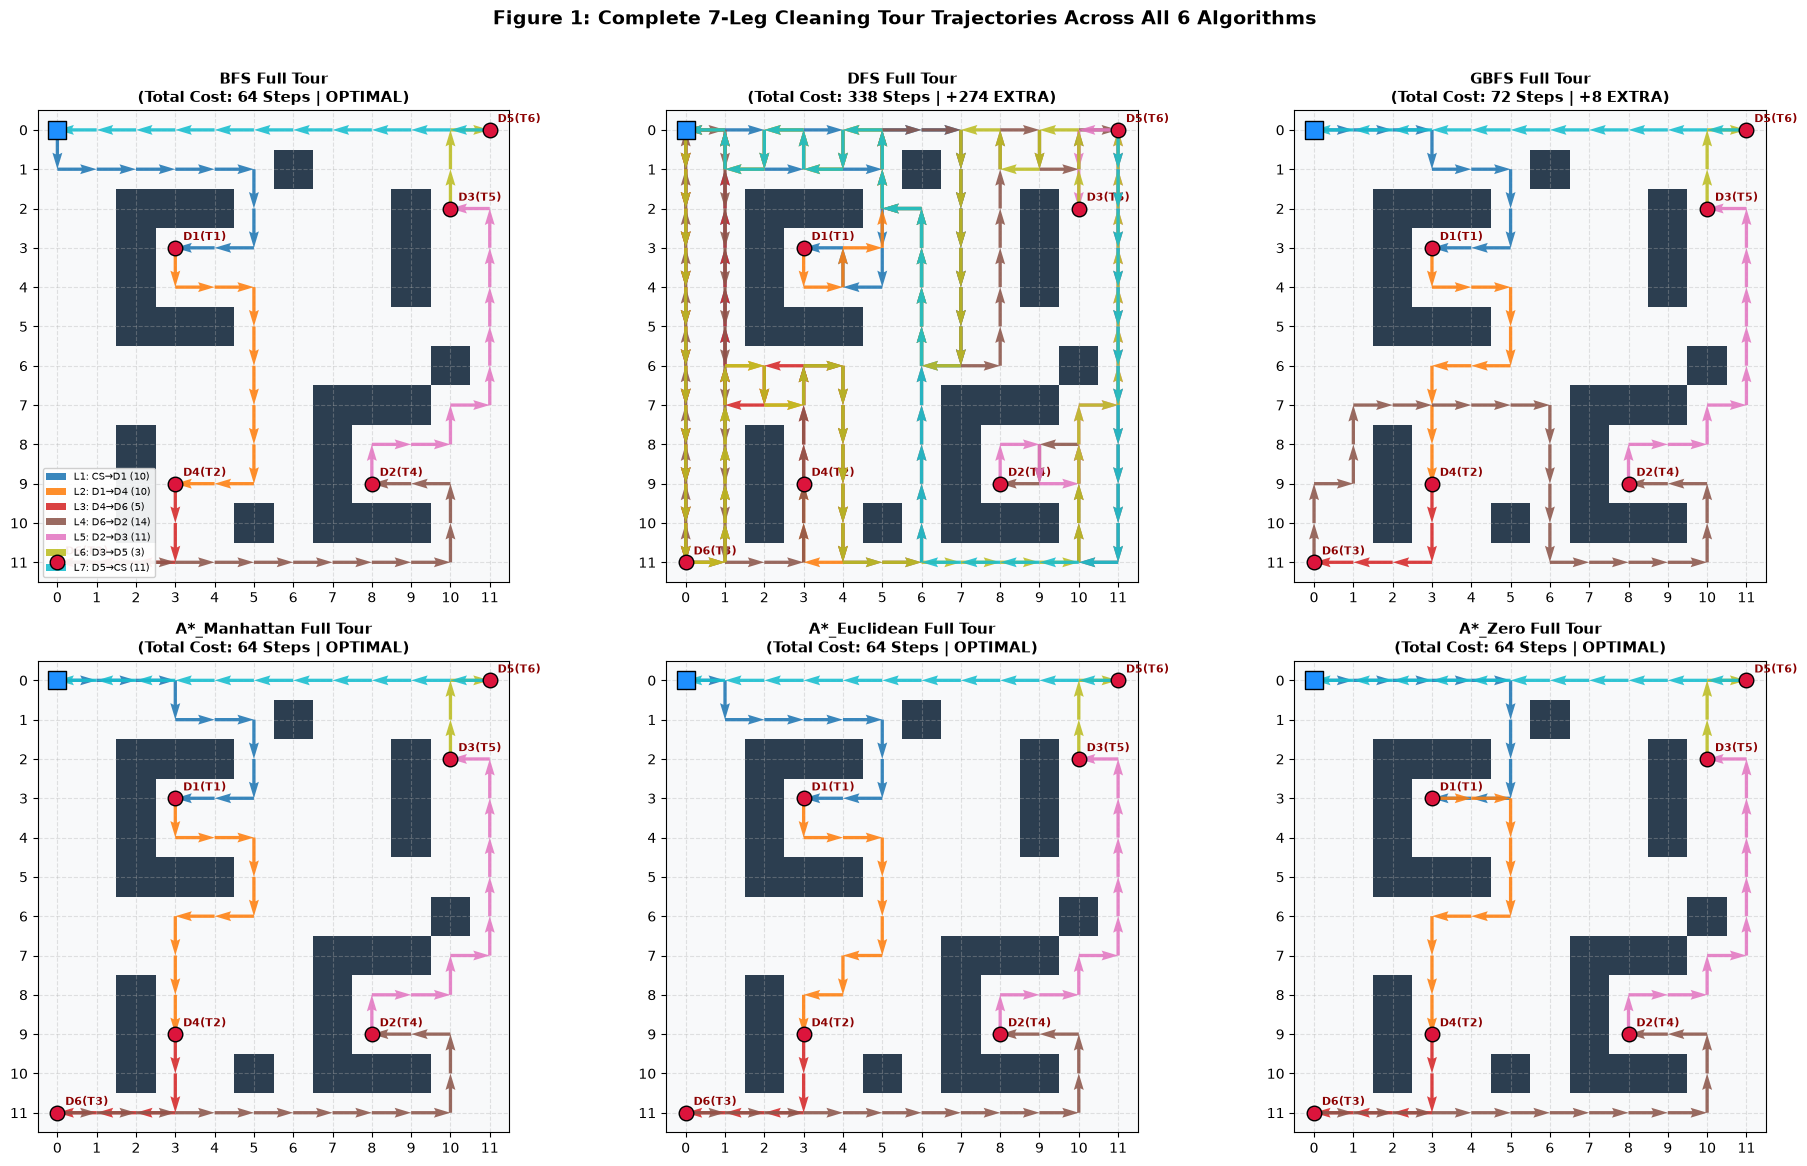

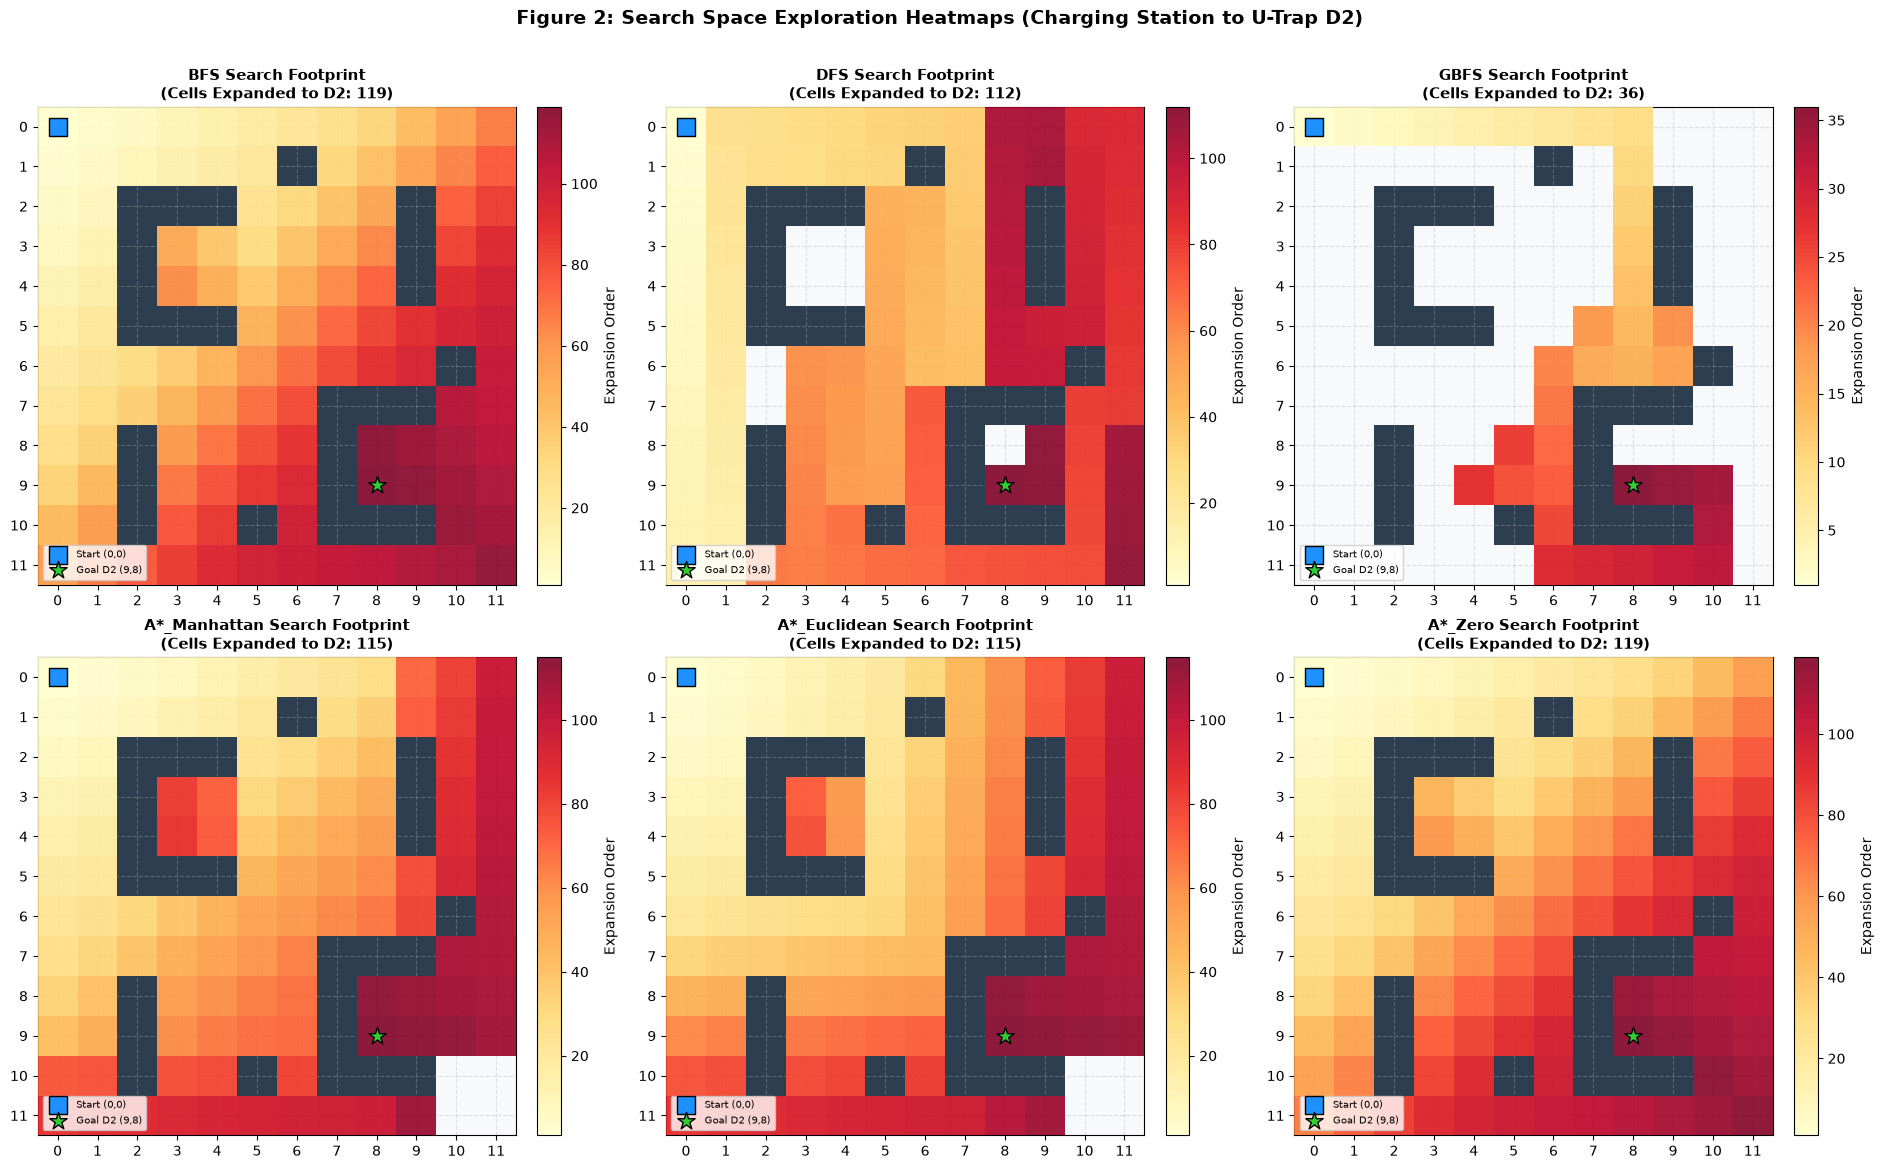

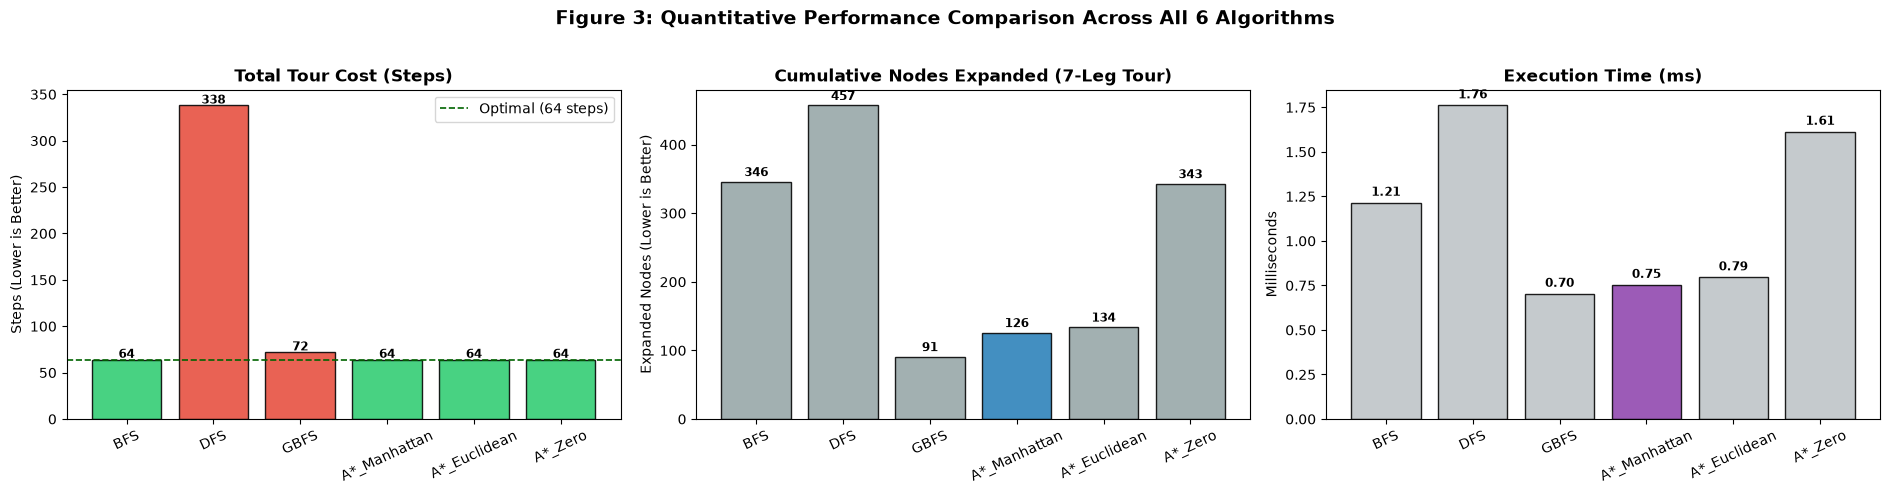

In [7]:
import math
import heapq
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ==============================================================================
# HELPER: RECORD CELL EXPANSION ORDER FOR ALL 6 SEARCH ALGORITHMS
# ==============================================================================
def compute_exploration_wave(grid, start, goal, algo):
    rows, cols = grid.shape
    wave = np.full((rows, cols), np.nan)
    moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    step = 0

    def heuristic(r, c):
        if algo in ("A*_Manhattan", "GBFS"):
            return abs(r - goal[0]) + abs(c - goal[1])
        elif algo == "A*_Euclidean":
            return math.hypot(r - goal[0], c - goal[1])
        return 0  # A*_Zero

    if algo == "BFS":
        frontier = deque([start])
        seen = {start}
        while frontier:
            curr = frontier.popleft()
            step += 1
            wave[curr] = step
            if curr == goal:
                break
            for dr, dc in moves:
                nr, nc = curr[0] + dr, curr[1] + dc
                if 0 <= nr < rows and 0 <= nc < cols and grid[nr, nc] == 0 and (nr, nc) not in seen:
                    seen.add((nr, nc))
                    frontier.append((nr, nc))

    elif algo == "DFS":
        stack = [start]
        seen = set()
        while stack:
            curr = stack.pop()
            if curr in seen:
                continue
            seen.add(curr)
            step += 1
            wave[curr] = step
            if curr == goal:
                break
            for dr, dc in reversed(moves):
                nr, nc = curr[0] + dr, curr[1] + dc
                if 0 <= nr < rows and 0 <= nc < cols and grid[nr, nc] == 0 and (nr, nc) not in seen:
                    stack.append((nr, nc))

    elif algo == "GBFS":
        pq = [(heuristic(*start), start)]
        seen = {start}
        while pq:
            _, curr = heapq.heappop(pq)
            step += 1
            wave[curr] = step
            if curr == goal:
                break
            for dr, dc in moves:
                nr, nc = curr[0] + dr, curr[1] + dc
                if 0 <= nr < rows and 0 <= nc < cols and grid[nr, nc] == 0 and (nr, nc) not in seen:
                    seen.add((nr, nc))
                    heapq.heappush(pq, (heuristic(nr, nc), (nr, nc)))

    else:  # A*_Manhattan, A*_Euclidean, A*_Zero
        pq = [(heuristic(*start), 0, start)]
        best_g = {start: 0}
        while pq:
            _, g, curr = heapq.heappop(pq)
            if g > best_g.get(curr, float("inf")):
                continue
            if np.isnan(wave[curr]):
                step += 1
                wave[curr] = step
            if curr == goal:
                break
            for dr, dc in moves:
                nr, nc = curr[0] + dr, curr[1] + dc
                if 0 <= nr < rows and 0 <= nc < cols and grid[nr, nc] == 0:
                    ng = g + 1
                    if ng < best_g.get((nr, nc), float("inf")):
                        best_g[(nr, nc)] = ng
                        heapq.heappush(pq, (ng + heuristic(nr, nc), ng, (nr, nc)))

    return wave, step


all_algos = ["BFS", "DFS", "GBFS", "A*_Manhattan", "A*_Euclidean", "A*_Zero"]
wall_cmap = ListedColormap(["#f8f9fa", "#2c3e50"])
cs = env_valid["charging_station"]
waypoints = [("CS", cs)] + [(task, env_valid["dirty_map"][task]) for task, _ in ordered_tasks] + [("CS", cs)]
leg_colors = plt.cm.tab10(np.linspace(0, 1, len(waypoints) - 1))

# ==============================================================================
# FIGURE 1: 2x3 GRID OF FULL-TOUR TRAJECTORIES (ALL 6 ALGORITHMS)
# ==============================================================================
fig1, axes1 = plt.subplots(2, 3, figsize=(19, 11.5))
axes1 = axes1.flatten()

for idx, algo_name in enumerate(all_algos):
    ax = axes1[idx]
    ax.imshow(grid_valid, cmap=wall_cmap)

    algo_total_cost = 0
    for i in range(len(waypoints) - 1):
        name_a, pt_a = waypoints[i]
        name_b, pt_b = waypoints[i + 1]
        leg_path, leg_cost, _ = search(grid_valid, pt_a, pt_b, algorithm=algo_name)
        algo_total_cost += leg_cost

        rows_l = [p[0] for p in leg_path]
        cols_l = [p[1] for p in leg_path]
        ax.quiver(
            cols_l[:-1], rows_l[:-1], np.diff(cols_l), np.diff(rows_l),
            angles="xy", scale_units="xy", scale=1, color=leg_colors[i],
            width=0.007, alpha=0.88, zorder=4,
            label=f"L{i+1}: {name_a}→{name_b} ({leg_cost})" if idx == 0 else None
        )

    # Plot Charging Station & Dirty Spots
    ax.scatter(cs[1], cs[0], c="dodgerblue", edgecolors="black", s=160, marker="s", zorder=6)
    for task, slot in ordered_tasks:
        dr, dc = env_valid["dirty_map"][task]
        slot_str = slot if str(slot).startswith("T") else f"T{slot}"
        ax.scatter(dc, dr, c="crimson", edgecolors="black", s=110, zorder=6)
        ax.text(dc + 0.2, dr - 0.2, f"{task}({slot_str})", fontsize=8, fontweight="bold", color="darkred")

    status_tag = "OPTIMAL" if algo_total_cost == best_tour_cost else f"+{algo_total_cost - best_tour_cost} EXTRA"
    ax.set_title(f"{algo_name} Full Tour\n(Total Cost: {algo_total_cost} Steps | {status_tag})", fontweight="bold", fontsize=11)
    ax.set_xticks(range(env_valid["cols"]))
    ax.set_yticks(range(env_valid["rows"]))
    ax.grid(True, linestyle="--", alpha=0.35)
    if idx == 0:
        ax.legend(loc="lower left", fontsize=7, framealpha=0.92)

fig1.suptitle("Figure 1: Complete 7-Leg Cleaning Tour Trajectories Across All 6 Algorithms", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# ==============================================================================
# FIGURE 2: 2x3 GRID OF EXPLORATION WAVE HEATMAPS (ALL 6 ALGORITHMS TO D2)
# ==============================================================================
fig2, axes2 = plt.subplots(2, 3, figsize=(19, 11.5))
axes2 = axes2.flatten()
trap_goal = env_valid["dirty_map"]["D2"]

for idx, algo_name in enumerate(all_algos):
    ax = axes2[idx]
    wave_mat, exp_count = compute_exploration_wave(grid_valid, cs, trap_goal, algo_name)

    ax.imshow(grid_valid, cmap=wall_cmap)
    im = ax.imshow(wave_mat, cmap="YlOrRd", alpha=0.9, zorder=3)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Expansion Order")

    ax.scatter(cs[1], cs[0], c="dodgerblue", edgecolors="black", s=150, marker="s", zorder=5, label="Start (0,0)")
    ax.scatter(trap_goal[1], trap_goal[0], c="limegreen", edgecolors="black", s=170, marker="*", zorder=5, label="Goal D2 (9,8)")
    ax.set_title(f"{algo_name} Search Footprint\n(Cells Expanded to D2: {exp_count})", fontweight="bold", fontsize=11)
    ax.set_xticks(range(env_valid["cols"]))
    ax.set_yticks(range(env_valid["rows"]))
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(loc="lower left", fontsize=7.5)

fig2.suptitle("Figure 2: Search Space Exploration Heatmaps (Charging Station to U-Trap D2)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# ==============================================================================
# FIGURE 3: QUANTITATIVE MULTI-ALGORITHM BENCHMARK BAR CHARTS
# ==============================================================================
fig3, (ax_cost, ax_exp, ax_time) = plt.subplots(1, 3, figsize=(19, 4.8))
algos = df_valid_results["Algorithm"]
costs = df_valid_results["Tour Cost (Steps)"]
nodes = df_valid_results["Nodes Expanded"]
times = df_valid_results["Exec Time (ms)"]

# 1. Tour Cost
c_colors = ["#2ecc71" if c == costs.min() else "#e74c3c" for c in costs]
b1 = ax_cost.bar(algos, costs, color=c_colors, edgecolor="black", alpha=0.88)
ax_cost.axhline(costs.min(), color="darkgreen", linestyle="--", linewidth=1.2, label=f"Optimal ({costs.min()} steps)")
ax_cost.set_title("Total Tour Cost (Steps)", fontweight="bold")
ax_cost.set_ylabel("Steps (Lower is Better)")
ax_cost.tick_params(axis="x", rotation=25)
ax_cost.legend()
for bar in b1:
    ax_cost.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, int(bar.get_height()), ha="center", fontweight="bold", fontsize=8.5)

# 2. Cumulative Nodes Expanded
e_colors = ["#2980b9" if a == "A*_Manhattan" else "#95a5a6" for a in algos]
b2 = ax_exp.bar(algos, nodes, color=e_colors, edgecolor="black", alpha=0.88)
ax_exp.set_title("Cumulative Nodes Expanded (7-Leg Tour)", fontweight="bold")
ax_exp.set_ylabel("Expanded Nodes (Lower is Better)")
ax_exp.tick_params(axis="x", rotation=25)
for bar in b2:
    ax_exp.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 8, int(bar.get_height()), ha="center", fontweight="bold", fontsize=8.5)

# 3. CPU Execution Time
t_colors = ["#8e44ad" if a == "A*_Manhattan" else "#bdc3c7" for a in algos]
b3 = ax_time.bar(algos, times, color=t_colors, edgecolor="black", alpha=0.88)
ax_time.set_title("Execution Time (ms)", fontweight="bold")
ax_time.set_ylabel("Milliseconds")
ax_time.tick_params(axis="x", rotation=25)
for bar in b3:
    ax_time.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.04, f"{bar.get_height():.2f}", ha="center", fontweight="bold", fontsize=8.5)

fig3.suptitle("Figure 3: Quantitative Performance Comparison Across All 6 Algorithms", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# **Phase 7: Benchmark Validation — Sample Environment & Schedule Verification (8×8 Grid)**

Validates the full CSP + Navigation pipeline on the handout's 8×8 sample benchmark (`Environment_Sample.txt` and `Schedule_Sample.txt`), auditing every precedence, deadline, and exclusivity constraint. Benchmarks A* Manhattan against BFS (both optimal at **34 steps**, with A* expanding **57** nodes vs. **144** for BFS), prints untruncated leg paths, and renders the 3-panel Initial → Trajectory → Cleaned Grid figure.

=== TEST RUN #2: SAMPLE ENVIRONMENT (8x8) & SCHEDULE VERIFICATION ===
CSP Generated Schedule : T1: Clean D2 at (3, 7) -> T2: Clean D1 at (0, 7) -> T3: Clean D3 at (7, 7) -> T4: Clean D4 at (7, 0)
Visited Sequence       : Charging Station (0,0) -> D2 -> D1 -> D3 -> D4 -> Charging Station (0,0)
Execution Summary      : Total Movements = 34 | Navigation Cost = 34 | Nodes Expanded = 57 | Success = True
Search Comparison      : A*_Manhattan (Cost=34, Expanded=57) vs. BFS (Cost=34, Expanded=144)

--- TABLE A: CSP CONSTRAINT SATISFACTION AUDIT ---


,Constraint Type,Rule Specification,Assigned Values,Status
0,Precedence (Binary),D1 before D3,"D1=T2, D3=T3 (2 < 3)",SATISFIED
1,Precedence (Binary),D2 before D4,"D2=T1, D4=T4 (1 < 4)",SATISFIED
2,Precedence (Binary),D1 before D4,"D1=T2, D4=T4 (2 < 4)",SATISFIED
3,Latest-Slot (Unary),D3 no later than T3,D3=T3 (3 <= 3),SATISFIED
4,Latest-Slot (Unary),D2 no later than T3,D2=T1 (1 <= 3),SATISFIED
5,Slot Exclusivity (AllDiff),At most 1 task per time slot,"D2->T1, D1->T2, D3->T3, D4->T4",SATISFIED


--- TABLE B: LEG-BY-LEG JOURNEY & COMPUTED PATHS ---


,Leg,From,To,Steps (Cost),Nodes Expanded,Time (ms),Path
0,Leg 1,"Charging Station (0, 0)","D2 (T1) (3, 7)",10,29,0.1474,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5..."
1,Leg 2,"D2 (T1) (3, 7)","D1 (T2) (0, 7)",3,4,0.0226,"[(3, 7), (2, 7), (1, 7), (0, 7)]"
2,Leg 3,"D1 (T2) (0, 7)","D3 (T3) (7, 7)",7,8,0.0377,"[(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7..."
3,Leg 4,"D3 (T3) (7, 7)","D4 (T4) (7, 0)",7,8,0.0360,"[(7, 7), (7, 6), (7, 5), (7, 4), (7, 3), (7, 2..."
4,Leg 5,"D4 (T4) (7, 0)","Return to Base (0, 0)",7,8,0.0359,"[(7, 0), (6, 0), (5, 0), (4, 0), (3, 0), (2, 0..."



--- SAMPLE TOUR UNTRUNCATED LEG PATHS ---
Leg 1 (Charging Station (0, 0) -> D2 (T1) (3, 7)): [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7), (3, 7)]
Leg 2 (D2 (T1) (3, 7) -> D1 (T2) (0, 7)): [(3, 7), (2, 7), (1, 7), (0, 7)]
Leg 3 (D1 (T2) (0, 7) -> D3 (T3) (7, 7)): [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7), (7, 7)]
Leg 4 (D3 (T3) (7, 7) -> D4 (T4) (7, 0)): [(7, 7), (7, 6), (7, 5), (7, 4), (7, 3), (7, 2), (7, 1), (7, 0)]
Leg 5 (D4 (T4) (7, 0) -> Return to Base (0, 0)): [(7, 0), (6, 0), (5, 0), (4, 0), (3, 0), (2, 0), (1, 0), (0, 0)]


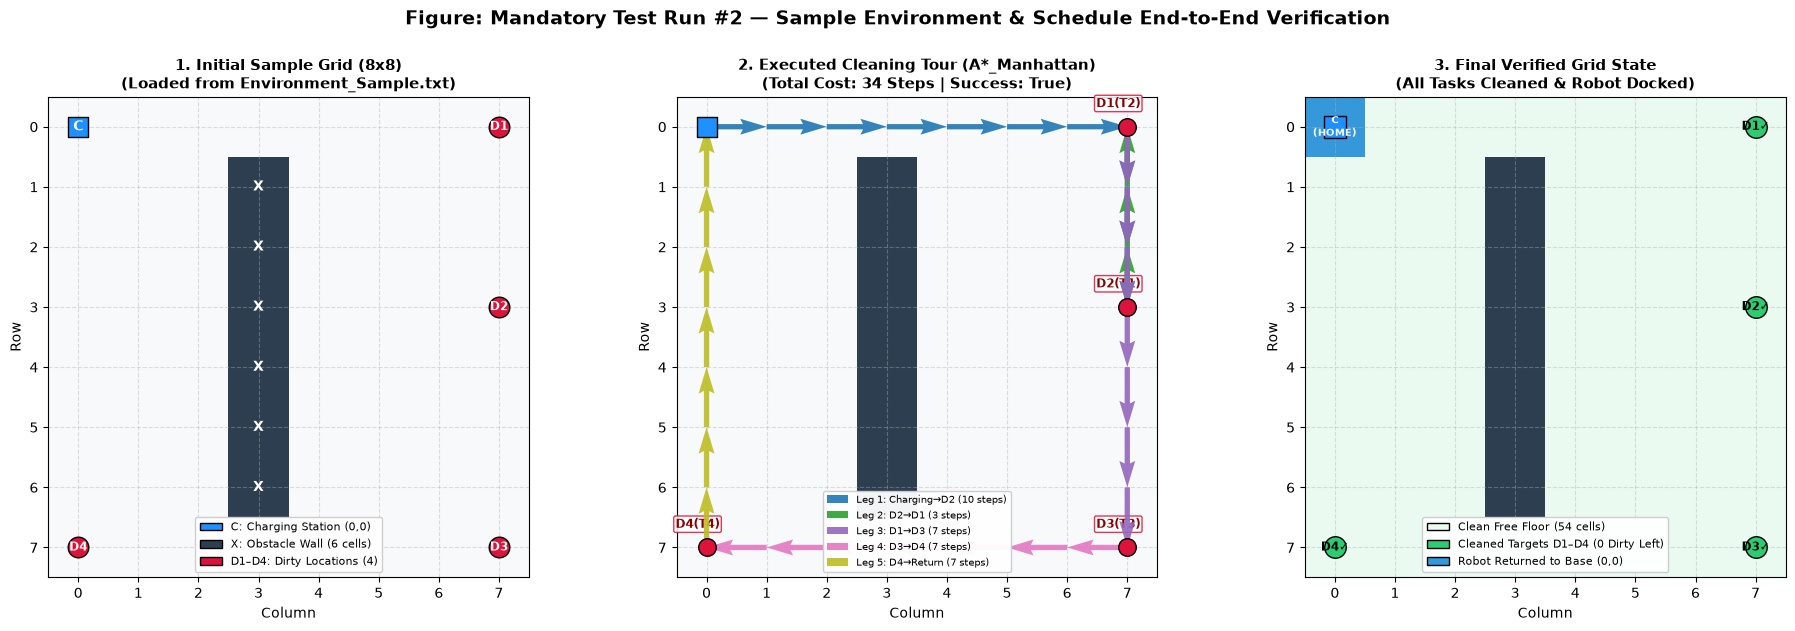

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ==============================================================================
# TEST RUN #2: SAMPLE ENVIRONMENT & SCHEDULE (SECTION 3 & SECTION 8.2)
# ==============================================================================
env_sample_txt = """8,8
6
(1,3), (2,3), (3,3), (4,3), (5,3), (6,3)
4
(0,7), (3,7), (7,7), (7,0)
(0,0)"""

sched_sample_txt = """4
3
(D1,D3)
(D2,D4)
(D1,D4)
2
(D3,T3)
(D2,T3)"""

if not os.path.exists("Environment_Sample.txt"):
    with open("Environment_Sample.txt", "w") as f:
        f.write(env_sample_txt.strip())

if not os.path.exists("Schedule_Sample.txt"):
    with open("Schedule_Sample.txt", "w") as f:
        f.write(sched_sample_txt.strip())

# 1. Load Sample Environment & Sample Schedule
env_samp = load_environment("Environment_Sample.txt")
sched_samp = load_schedule("Schedule_Sample.txt")
grid_samp = build_grid(env_samp)

# 2. Solve CSP Schedule & Verify All Constraints
samp_vars, samp_doms = build_csp_inputs(env_samp, sched_samp)
samp_schedule = backtracking_search(samp_vars, samp_doms, sched_samp)
ordered_samp_tasks = sorted(samp_schedule.items(), key=lambda x: slot_index(x[1]))

# 3. Execute Integrated Navigation Tour (A*_Manhattan & BFS Benchmark)
_, bfs_samp_cost, _ = execute_schedule(
    grid_samp, env_samp["charging_station"], samp_schedule, algorithm="BFS", dirty_map=env_samp["dirty_map"]
)
bfs_samp_exp = LAST_EXECUTION_TELEMETRY["total_expanded"]

samp_path, samp_cost, samp_success = execute_schedule(
    grid_samp,
    env_samp["charging_station"],
    samp_schedule,
    algorithm="A*_Manhattan",
    dirty_map=env_samp["dirty_map"]
)
samp_legs = LAST_EXECUTION_TELEMETRY["leg_details"]
samp_cleaned_grid = LAST_EXECUTION_TELEMETRY["cleaned_grid"]

# ==============================================================================
# TABLE 1: CSP SCHEDULE & CONSTRAINT SATISFACTION VERIFICATION GRID
# ==============================================================================
constraint_checks = []
for b, a in sched_samp["precedence"]:
    sb, sa = samp_schedule[b], samp_schedule[a]
    passed = slot_index(sb) < slot_index(sa)
    constraint_checks.append({
        "Constraint Type": "Precedence (Binary)",
        "Rule Specification": f"{b} before {a}",
        "Assigned Values": f"{b}={sb}, {a}={sa} ({slot_index(sb)} < {slot_index(sa)})",
        "Status": "SATISFIED" if passed else "VIOLATED"
    })

for task, latest in sched_samp["latest_slot"]:
    st = samp_schedule[task]
    passed = slot_index(st) <= slot_index(latest)
    constraint_checks.append({
        "Constraint Type": "Latest-Slot (Unary)",
        "Rule Specification": f"{task} no later than {latest}",
        "Assigned Values": f"{task}={st} ({slot_index(st)} <= {slot_index(latest)})",
        "Status": "SATISFIED" if passed else "VIOLATED"
    })

unique_slots = len(set(samp_schedule.values())) == len(samp_schedule)
constraint_checks.append({
    "Constraint Type": "Slot Exclusivity (AllDiff)",
    "Rule Specification": "At most 1 task per time slot",
    "Assigned Values": ", ".join([f"{t}->{s}" for t, s in ordered_samp_tasks]),
    "Status": "SATISFIED" if unique_slots else "VIOLATED"
})

print("=== TEST RUN #2: SAMPLE ENVIRONMENT (8x8) & SCHEDULE VERIFICATION ===")
print("CSP Generated Schedule :", " -> ".join([f"{s}: Clean {t} at {env_samp['dirty_map'][t]}" for t, s in ordered_samp_tasks]))
print("Visited Sequence       :", " -> ".join(["Charging Station (0,0)"] + LAST_EXECUTION_TELEMETRY["cleaned_tasks"] + ["Charging Station (0,0)"]))
print(f"Execution Summary      : Total Movements = {len(samp_path) - 1} | Navigation Cost = {samp_cost} | Nodes Expanded = {LAST_EXECUTION_TELEMETRY['total_expanded']} | Success = {samp_success}")
print(f"Search Comparison      : A*_Manhattan (Cost={samp_cost}, Expanded={LAST_EXECUTION_TELEMETRY['total_expanded']}) vs. BFS (Cost={bfs_samp_cost}, Expanded={bfs_samp_exp})\n")

print("--- TABLE A: CSP CONSTRAINT SATISFACTION AUDIT ---")
display(pd.DataFrame(constraint_checks))

print("--- TABLE B: LEG-BY-LEG JOURNEY & COMPUTED PATHS ---")
display(pd.DataFrame(samp_legs))

print("\n--- SAMPLE TOUR UNTRUNCATED LEG PATHS ---")
for leg in samp_legs:
    print(f"{leg['Leg']} ({leg['From']} -> {leg['To']}): {leg['Path']}")

# ==============================================================================
# FIGURE: 3-PANEL VISUAL VERIFICATION (INITIAL -> TRAJECTORY -> CLEANED GRID)
# ==============================================================================
fig, (ax_init, ax_traj, ax_done) = plt.subplots(1, 3, figsize=(19, 6))
cs_s = env_samp["charging_station"]
base_cmap = ListedColormap(["#f8f9fa", "#2c3e50"])

# ------------------------------------------------------------------------------
# PANEL 1: INITIAL 8x8 SAMPLE ENVIRONMENT
# ------------------------------------------------------------------------------
ax_init.imshow(grid_samp, cmap=base_cmap)
ax_init.scatter(cs_s[1], cs_s[0], c="dodgerblue", edgecolors="black", s=220, marker="s", zorder=6)
ax_init.text(cs_s[1], cs_s[0], "C", ha="center", va="center", color="white", fontweight="bold", fontsize=10, zorder=7)

for r in range(env_samp["rows"]):
    for c in range(env_samp["cols"]):
        if grid_samp[r, c] == 1:
            ax_init.text(c, r, "X", ha="center", va="center", color="white", fontweight="bold", fontsize=10, zorder=5)

for task, (dr, dc) in env_samp["dirty_map"].items():
    ax_init.scatter(dc, dr, c="crimson", edgecolors="black", s=220, zorder=6)
    ax_init.text(dc, dr, task, ha="center", va="center", color="white", fontweight="bold", fontsize=8.5, zorder=7)

init_legend = [
    Patch(facecolor="dodgerblue", edgecolor="black", label="C: Charging Station (0,0)"),
    Patch(facecolor="#2c3e50", edgecolor="black", label="X: Obstacle Wall (6 cells)"),
    Patch(facecolor="crimson", edgecolor="black", label="D1–D4: Dirty Locations (4)")
]
ax_init.legend(handles=init_legend, loc="lower center", fontsize=8, framealpha=0.95)
ax_init.set_title("1. Initial Sample Grid (8x8)\n(Loaded from Environment_Sample.txt)", fontweight="bold", fontsize=11)

# ------------------------------------------------------------------------------
# PANEL 2: INTEGRATED A* NAVIGATION TRAJECTORY
# ------------------------------------------------------------------------------
ax_traj.imshow(grid_samp, cmap=base_cmap)
leg_palette = plt.cm.tab10(np.linspace(0, 0.85, len(samp_legs)))

for i, leg in enumerate(samp_legs):
    lpath = leg["Path"]
    rows_l = [p[0] for p in lpath]
    cols_l = [p[1] for p in lpath]
    ax_traj.quiver(
        cols_l[:-1], rows_l[:-1], np.diff(cols_l), np.diff(rows_l),
        angles="xy", scale_units="xy", scale=1, color=leg_palette[i],
        width=0.011, alpha=0.9, zorder=4,
        label=f"{leg['Leg']}: {leg['From'].split()[0]}→{leg['To'].split()[0]} ({leg['Steps (Cost)']} steps)"
    )

ax_traj.scatter(cs_s[1], cs_s[0], c="dodgerblue", edgecolors="black", s=200, marker="s", zorder=6)
for task, slot in ordered_samp_tasks:
    dr, dc = env_samp["dirty_map"][task]
    ax_traj.scatter(dc, dr, c="crimson", edgecolors="black", s=160, zorder=6)
    ax_traj.text(dc - 0.15, dr - 0.28, f"{task}({slot})", ha="center", va="bottom",
                 fontsize=8.5, fontweight="bold", color="darkred",
                 bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="crimson", alpha=0.85))

ax_traj.legend(loc="lower center", fontsize=7.5, framealpha=0.95)
ax_traj.set_title(f"2. Executed Cleaning Tour (A*_Manhattan)\n(Total Cost: {samp_cost} Steps | Success: {samp_success})", fontweight="bold", fontsize=11)

# ------------------------------------------------------------------------------
# PANEL 3: FINAL GRID AFTER CLEANING COMPLETION
# ------------------------------------------------------------------------------
done_cmap = ListedColormap(["#eafaf1", "#2c3e50", "#3498db"])
ax_done.imshow(samp_cleaned_grid, cmap=done_cmap, vmin=0, vmax=2)

ax_done.scatter(cs_s[1], cs_s[0], c="dodgerblue", edgecolors="black", s=240, marker="s", zorder=6)
ax_done.text(cs_s[1], cs_s[0], "C\n(HOME)", ha="center", va="center", color="white", fontweight="bold", fontsize=7.5, zorder=7)

for task, (dr, dc) in env_samp["dirty_map"].items():
    ax_done.scatter(dc, dr, c="#2ecc71", edgecolors="black", s=240, marker="o", zorder=6)
    ax_done.text(dc, dr, f"{task}✓", ha="center", va="center", color="black", fontweight="bold", fontsize=8.5, zorder=7)

done_legend = [
    Patch(facecolor="#eafaf1", edgecolor="black", label="Clean Free Floor (54 cells)"),
    Patch(facecolor="#2ecc71", edgecolor="black", label="Cleaned Targets D1–D4 (0 Dirty Left)"),
    Patch(facecolor="#3498db", edgecolor="black", label="Robot Returned to Base (0,0)")
]
ax_done.legend(handles=done_legend, loc="lower center", fontsize=8, framealpha=0.95)
ax_done.set_title("3. Final Verified Grid State\n(All Tasks Cleaned & Robot Docked)", fontweight="bold", fontsize=11)

for ax in (ax_init, ax_traj, ax_done):
    ax.set_xticks(range(env_samp["cols"]))
    ax.set_yticks(range(env_samp["rows"]))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.grid(True, linestyle="--", alpha=0.4)

fig.suptitle("Figure: Mandatory Test Run #2 — Sample Environment & Schedule End-to-End Verification", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# **Phase 8: Error Diagnostics — Spatial Enclosure & Temporal Cycle Auditing**

Tests graceful failure handling on two adversarial inputs: `Environment_Error.txt` (where `D2` at `(9, 8)` is sealed inside obstacles, causing all 6 search algorithms to exhaust the 116 reachable cells and `execute_schedule` to return `([], inf, False)`) and `Schedule_Error.txt` (which contains the infeasible precedence cycle `D1 -> D3 -> D2 -> D1`, causing the CSP solver to return `None` with an explicit cycle diagnostic).

In [9]:
# 1. Create Environment_Error.txt (Dirty task D2 at (9,8) completely walled off by obstacles)
import os

env_error_content = """12,12
26
(2,2), (2,3), (2,4), (3,2), (4,2), (5,2), (5,3), (5,4), (7,7), (7,8), (7,9), (8,7), (9,7), (10,7), (10,8), (10,9), (8,9), (9,9), (2,9), (3,9), (4,9), (8,2), (9,2), (10,2), (1,6), (6,10)
6
(3,3), (9,8), (2,10), (9,3), (0,11), (11,0)
(0,0)
"""
if not os.path.exists("Environment_Error.txt"):
    with open("Environment_Error.txt", "w") as f:
        f.write(env_error_content.strip())
    print("Created Environment_Error.txt.")
else:
    print("Using existing Environment_Error.txt (not overwritten).")

# 2. Create Schedule_Error.txt (Contains a directed precedence cycle: D1 -> D3 -> D2 -> D1)
sched_error_content = """7
3
(D1,D3)
(D3,D2)
(D2,D1)
2
(D1,T3)
(D4,T5)
"""
if not os.path.exists("Schedule_Error.txt"):
    with open("Schedule_Error.txt", "w") as f:
        f.write(sched_error_content.strip())
    print("Created Schedule_Error.txt.")
else:
    print("Using existing Schedule_Error.txt (not overwritten).")


Using existing Environment_Error.txt (not overwritten).
Using existing Schedule_Error.txt (not overwritten).


In [10]:
import time
from collections import deque, defaultdict
import numpy as np
import pandas as pd

# ==============================================================================
# PART A: ENVIRONMENT_ERROR.TXT DIAGNOSTIC (FLOOD-FILL + 6-ALGORITHM CHECK)
# ==============================================================================
env_err = load_environment("Environment_Error.txt")
grid_err = build_grid(env_err)
cs_err = env_err["charging_station"]

# 1. Flood-Fill BFS from Charging Station to find all reachable cells
reachable_cells = {cs_err}
q = deque([cs_err])
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]

while q:
    r, c = q.popleft()
    for dr, dc in moves:
        nr, nc = r + dr, c + dc
        if 0 <= nr < env_err["rows"] and 0 <= nc < env_err["cols"]:
            if grid_err[nr, nc] == 0 and (nr, nc) not in reachable_cells:
                reachable_cells.add((nr, nc))
                q.append((nr, nc))

total_cells = env_err["rows"] * env_err["cols"]
obstacle_count = int(grid_err.sum())
reachable_count = len(reachable_cells)
sealed_free_count = total_cells - obstacle_count - reachable_count

blocked_tasks = {
    task: coord for task, coord in env_err["dirty_map"].items()
    if coord not in reachable_cells
}

print("=== ERROR RUN 1: ENVIRONMENT_ERROR.TXT SPATIAL REACHABILITY DIAGNOSTIC ===")
print(f"  Grid Size: {env_err['rows']}x{env_err['cols']} ({total_cells} total cells)")
print(f"  Reachable Floor: {reachable_count} cells | Obstacles: {obstacle_count} cells | Sealed Unreachable Pocket: {sealed_free_count} cells")
for task, coord in blocked_tasks.items():
    print(f"  [CRITICAL FAILURE] Task {task} at {coord} is completely enclosed by obstacles!")

# 2. Verify all 6 search algorithms gracefully detect unreachability to the blocked task
first_blocked_task = next(iter(blocked_tasks))
blocked_goal = blocked_tasks[first_blocked_task]
err_algo_rows = []

for algo in ["BFS", "DFS", "GBFS", "A*_Manhattan", "A*_Euclidean", "A*_Zero"]:
    t0 = time.perf_counter()
    path_res, cost_res, exp_res = search(grid_err, cs_err, blocked_goal, algorithm=algo)
    exec_ms = round((time.perf_counter() - t0) * 1000, 4)
    found = bool(path_res) and cost_res != float("inf")
    err_algo_rows.append({
        "Algorithm": algo,
        "Target": f"{first_blocked_task} {blocked_goal}",
        "Path Found": found,
        "Reachable Space Exhausted (Nodes)": exp_res,
        "Exec Time (ms)": exec_ms,
        "Failure Handling": "Graceful Termination (Unreachable)" if not found else "Found"
    })

df_env_err_audit = pd.DataFrame(err_algo_rows)
display(df_env_err_audit)

# 3. Verify integrated execute_schedule() aborts cleanly using exact 3-tuple return
err_full_path, err_total_cost, err_success = execute_schedule(
    grid_err, cs_err, optimal_sched, algorithm="A*_Manhattan", dirty_map=env_err["dirty_map"]
)
print(
    f"  Integrated execute_schedule() Output -> Path: {err_full_path} | "
    f"Cost: {err_total_cost} | Success: {err_success} (Unreachable Target)\n"
)

# ==============================================================================
# PART B: SCHEDULE_ERROR.TXT DIAGNOSTIC (DOMAIN PRUNING + CSP + CYCLE DETECTION)
# ==============================================================================
sched_err = load_schedule("Schedule_Error.txt")
num_slots_err = sched_err.get("num_slots", 7)
prec_rules_err = sched_err.get("precedence", [])
deadline_rules_err = sched_err.get("latest_slot", sched_err.get("deadlines", []))

# Normalize deadline dictionary: task -> latest integer slot
deadlines_map = {}
for item in deadline_rules_err:
    t_name, raw_slot = item[0], item[1]
    deadlines_map[t_name] = int(str(raw_slot).lstrip("T"))

# Run CSP backtracking solver to verify infeasible detection
vars_err, doms_err = build_csp_inputs(env_err, sched_err)
csp_err_solution = backtracking_search(vars_err, doms_err, sched_err)

# Build directed precedence graph & run DFS cycle detection
adj_prec = defaultdict(list)
for u, v in prec_rules_err:
    adj_prec[u].append(v)

all_tasks_err = sorted(env_err["dirty_map"].keys())
state = {t: 0 for t in all_tasks_err}  # 0=unvisited, 1=visiting, 2=visited
detected_cycles = []

def dfs_find_cycles(node, path_stack):
    state[node] = 1
    path_stack.append(node)
    for nxt in adj_prec[node]:
        if state.get(nxt, 0) == 1:
            cycle_start = path_stack.index(nxt)
            detected_cycles.append(path_stack[cycle_start:] + [nxt])
        elif state.get(nxt, 0) == 0:
            dfs_find_cycles(nxt, path_stack)
    path_stack.pop()
    state[node] = 2

for t in all_tasks_err:
    if state[t] == 0:
        dfs_find_cycles(t, [])

primary_cycle = detected_cycles[0] if detected_cycles else []
cycle_nodes = set(primary_cycle)
cycle_edges = set(zip(primary_cycle[:-1], primary_cycle[1:]))

print("=== ERROR RUN 2: SCHEDULE_ERROR.TXT TEMPORAL & CYCLE DIAGNOSTIC ===")
print(f"  Available Slots: T1..T{num_slots_err} | Precedence Rules: {len(prec_rules_err)} | Deadline Rules: {len(deadline_rules_err)}")
print(f"  CSP Solver Result: {csp_err_solution} (No Feasible Schedule Exists)")
if primary_cycle:
    print(f"  [CRITICAL FAILURE] Precedence Cycle Detected: {' -> '.join(primary_cycle)}")
    print(f"  Mathematical Contradiction: {' < '.join([f'Slot({n})' for n in primary_cycle])} (Impossible)")

# Build task-level constraint summary table
sched_audit_rows = []
for t in all_tasks_err:
    max_s = deadlines_map.get(t, num_slots_err)
    pruned_dom = [f"T{s}" for s in range(1, max_s + 1)]
    preds = [u for u, v in prec_rules_err if v == t]
    succs = [v for u, v in prec_rules_err if u == t]
    sched_audit_rows.append({
        "Task": t,
        "Allowed Slots (After Deadlines)": ", ".join(pruned_dom),
        "Must Follow (Predecessors)": ", ".join(preds) if preds else "None",
        "Must Precede (Successors)": ", ".join(succs) if succs else "None",
        "Diagnostic Status": "INFEASIBLE (In Precedence Cycle)" if t in cycle_nodes else "OK (Blocked by Global Failure)"
    })

df_sched_err_audit = pd.DataFrame(sched_audit_rows)
display(df_sched_err_audit)

=== ERROR RUN 1: ENVIRONMENT_ERROR.TXT SPATIAL REACHABILITY DIAGNOSTIC ===
  Grid Size: 12x12 (144 total cells)
  Reachable Floor: 116 cells | Obstacles: 26 cells | Sealed Unreachable Pocket: 2 cells
  [CRITICAL FAILURE] Task D2 at (9, 8) is completely enclosed by obstacles!


,Algorithm,Target,Path Found,Reachable Space Exhausted (Nodes),Exec Time (ms),Failure Handling
0,BFS,"D2 (9, 8)",False,116,0.4337,Graceful Termination (Unreachable)
1,DFS,"D2 (9, 8)",False,116,0.4544,Graceful Termination (Unreachable)
2,GBFS,"D2 (9, 8)",False,116,0.4876,Graceful Termination (Unreachable)
3,A*_Manhattan,"D2 (9, 8)",False,116,0.5822,Graceful Termination (Unreachable)
4,A*_Euclidean,"D2 (9, 8)",False,116,0.5903,Graceful Termination (Unreachable)
5,A*_Zero,"D2 (9, 8)",False,116,0.5461,Graceful Termination (Unreachable)


  Integrated execute_schedule() Output -> Path: [] | Cost: inf | Success: False (Unreachable Target)

=== ERROR RUN 2: SCHEDULE_ERROR.TXT TEMPORAL & CYCLE DIAGNOSTIC ===
  Available Slots: T1..T7 | Precedence Rules: 3 | Deadline Rules: 2
  CSP Solver Result: None (No Feasible Schedule Exists)
  [CRITICAL FAILURE] Precedence Cycle Detected: D1 -> D3 -> D2 -> D1
  Mathematical Contradiction: Slot(D1) < Slot(D3) < Slot(D2) < Slot(D1) (Impossible)


,Task,Allowed Slots (After Deadlines),Must Follow (Predecessors),Must Precede (Successors),Diagnostic Status
0,D1,"T1, T2, T3",D2,D3,INFEASIBLE (In Precedence Cycle)
1,D2,"T1, T2, T3, T4, T5, T6, T7",D3,D1,INFEASIBLE (In Precedence Cycle)
2,D3,"T1, T2, T3, T4, T5, T6, T7",D1,D2,INFEASIBLE (In Precedence Cycle)
3,D4,"T1, T2, T3, T4, T5",None,None,OK (Blocked by Global Failure)
4,D5,"T1, T2, T3, T4, T5, T6, T7",None,None,OK (Blocked by Global Failure)
5,D6,"T1, T2, T3, T4, T5, T6, T7",None,None,OK (Blocked by Global Failure)


# **Phase 9: Failure Mode Visual Analytics — Reachability Maps & Precedence Cycle Graphs**

Visualizes both failure modes from Phase 8: a flood-fill spatial reachability map highlighting the sealed obstacle pocket isolating `D2`, and a directed precedence graph highlighting the contradictory `D1 -> D3 -> D2 -> D1` cycle.

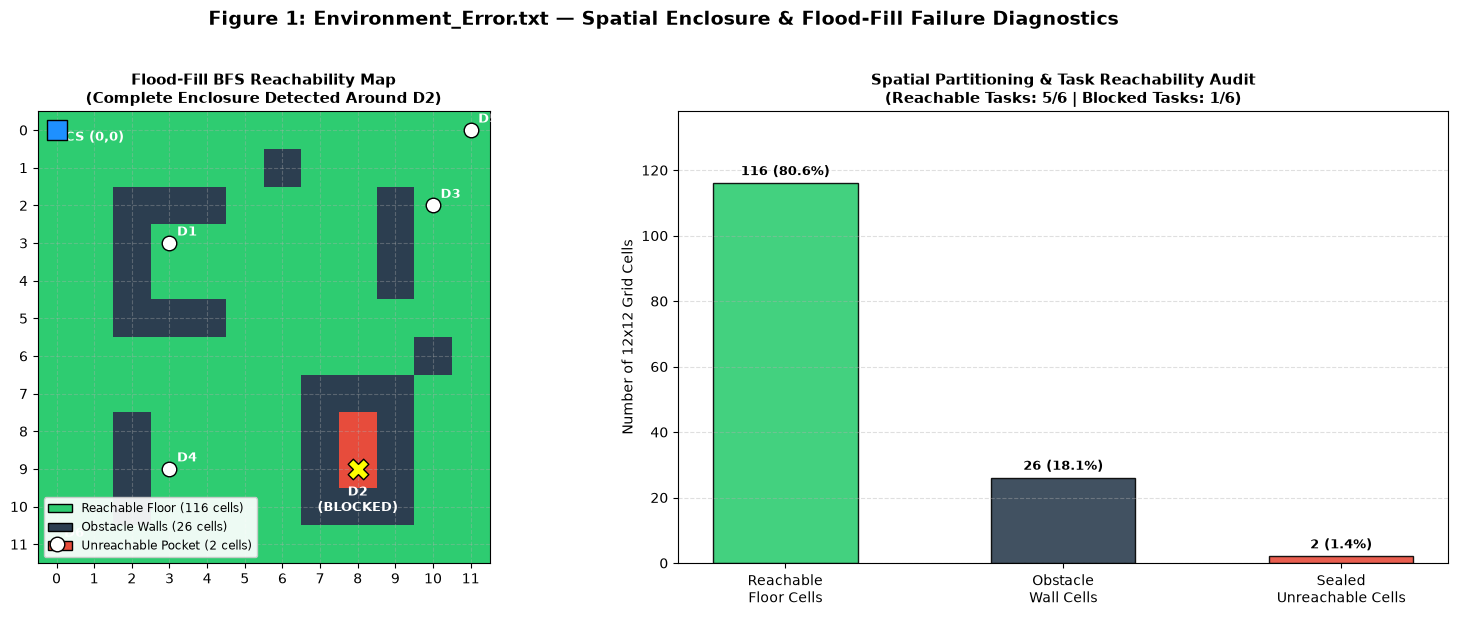

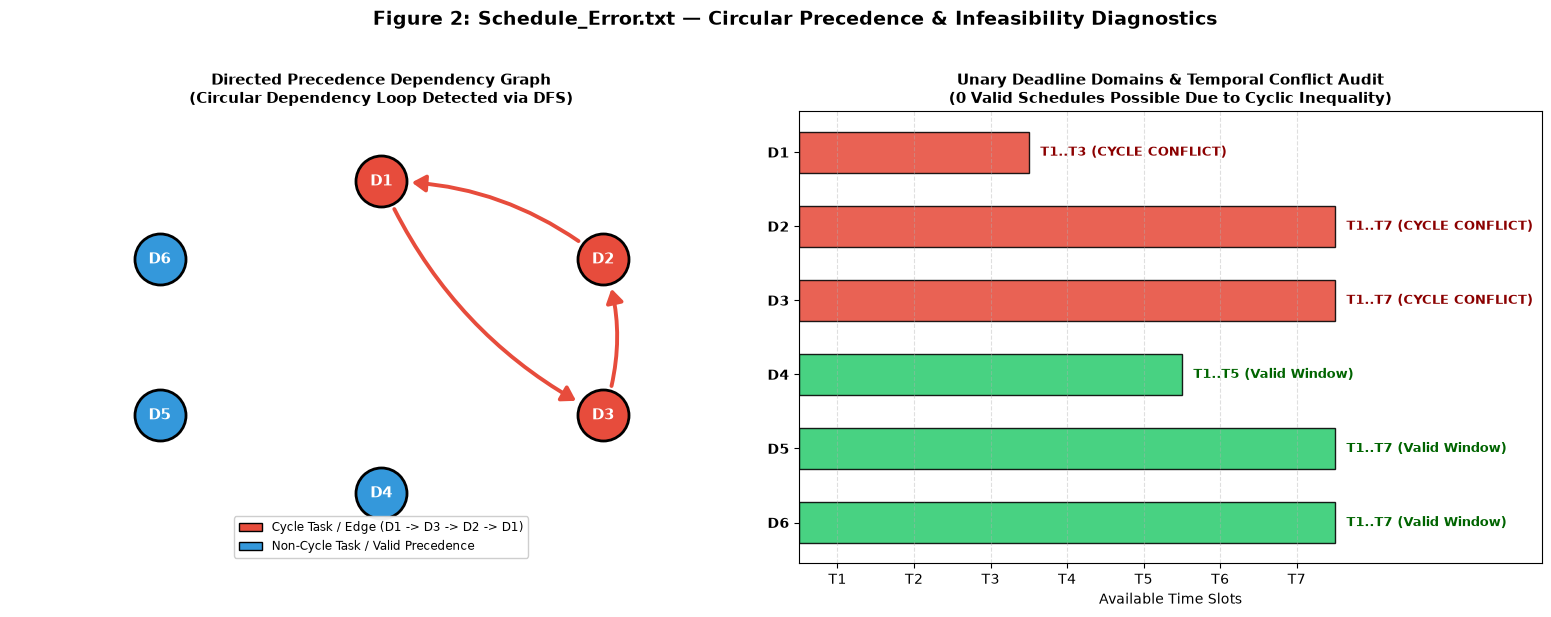

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ==============================================================================
# FIGURE 1: ENVIRONMENT_ERROR.TXT FLOOD-FILL & ACCESSIBILITY DIAGNOSTICS
# ==============================================================================
fig1, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(16, 6))

# Build 3-state diagnostic matrix: 0 = Green (Reachable), 1 = Dark Wall, 2 = Red (Blocked Pocket)
diag_grid = np.zeros_like(grid_err)
for r in range(env_err["rows"]):
    for c in range(env_err["cols"]):
        if grid_err[r, c] == 1:
            diag_grid[r, c] = 1
        elif (r, c) not in reachable_cells:
            diag_grid[r, c] = 2

err_cmap = ListedColormap(["#2ecc71", "#2c3e50", "#e74c3c"])
ax_map.imshow(diag_grid, cmap=err_cmap)

# Plot Charging Station
ax_map.scatter(cs_err[1], cs_err[0], c="dodgerblue", edgecolors="black", s=200, marker="s", zorder=6)
ax_map.text(cs_err[1] + 0.22, cs_err[0] + 0.28, "CS (0,0)", color="white", fontweight="bold", fontsize=9)

# Plot Dirty Tasks (Highlight Blocked Tasks)
for task, (dr, dc) in env_err["dirty_map"].items():
    if task in blocked_tasks:
        ax_map.scatter(dc, dr, c="yellow", edgecolors="black", s=220, marker="X", zorder=7)
        ax_map.text(dc, dr + 0.42, f"{task}\n(BLOCKED)", ha="center", va="top", color="white", fontweight="bold", fontsize=9)
    else:
        ax_map.scatter(dc, dr, c="white", edgecolors="black", s=110, zorder=6)
        ax_map.text(dc + 0.2, dr - 0.2, task, color="white", fontweight="bold", fontsize=9)

legend_patches = [
    Patch(facecolor="#2ecc71", edgecolor="black", label=f"Reachable Floor ({reachable_count} cells)"),
    Patch(facecolor="#2c3e50", edgecolor="black", label=f"Obstacle Walls ({obstacle_count} cells)"),
    Patch(facecolor="#e74c3c", edgecolor="black", label=f"Unreachable Pocket ({sealed_free_count} cells)")
]
ax_map.legend(handles=legend_patches, loc="lower left", fontsize=8.5, framealpha=0.92)
ax_map.set_title("Flood-Fill BFS Reachability Map\n(Complete Enclosure Detected Around D2)", fontweight="bold", fontsize=11)
ax_map.set_xticks(range(env_err["cols"]))
ax_map.set_yticks(range(env_err["rows"]))
ax_map.grid(True, linestyle="--", alpha=0.35)

# Right Panel: Grid Cell & Dirty Task Accessibility Breakdown
categories = ["Reachable\nFloor Cells", "Obstacle\nWall Cells", "Sealed\nUnreachable Cells"]
counts = [reachable_count, obstacle_count, sealed_free_count]
bar_colors = ["#2ecc71", "#2c3e50", "#e74c3c"]

bars = ax_bar.bar(categories, counts, color=bar_colors, edgecolor="black", width=0.52, alpha=0.9)
ax_bar.set_ylim(0, max(counts) + 22)
ax_bar.set_ylabel("Number of 12x12 Grid Cells")
ax_bar.set_title(
    f"Spatial Partitioning & Task Reachability Audit\n(Reachable Tasks: {len(env_err['dirty_map']) - len(blocked_tasks)}/6 | Blocked Tasks: {len(blocked_tasks)}/6)",
    fontweight="bold", fontsize=11
)
ax_bar.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    h = bar.get_height()
    pct = (h / total_cells) * 100
    ax_bar.text(bar.get_x() + bar.get_width()/2, h + 2.5, f"{int(h)} ({pct:.1f}%)", ha="center", fontweight="bold", fontsize=9.5)

fig1.suptitle("Figure 1: Environment_Error.txt — Spatial Enclosure & Flood-Fill Failure Diagnostics", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# FIGURE 2: SCHEDULE_ERROR.TXT PRECEDENCE CYCLE & SLOT DOMAIN DIAGNOSTICS
# ==============================================================================
fig2, (ax_graph, ax_slots) = plt.subplots(1, 2, figsize=(16, 6))

# Left Panel: Directed Precedence Graph Highlighting the Cycle
ax_graph.set_xlim(-1.45, 1.45)
ax_graph.set_ylim(-1.45, 1.45)
ax_graph.axis("off")

n_tasks = len(all_tasks_err)
angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, n_tasks, endpoint=False)
node_pos = {task: (np.cos(ang), np.sin(ang)) for task, ang in zip(all_tasks_err, angles)}

# Draw Directed Edges
for u, v in prec_rules_err:
    x1, y1 = node_pos[u]
    x2, y2 = node_pos[v]
    is_cycle_edge = (u, v) in cycle_edges
    edge_color = "#e74c3c" if is_cycle_edge else "#7f8c8d"
    edge_lw = 2.8 if is_cycle_edge else 1.5
    rad = 0.18 if is_cycle_edge else 0.08

    ax_graph.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-|>,head_length=0.8,head_width=0.5",
            color=edge_color, lw=edge_lw, shrinkA=22, shrinkB=22,
            connectionstyle=f"arc3,rad={rad}"
        ),
        zorder=4 if is_cycle_edge else 2
    )

# Draw Task Nodes
for task, (x, y) in node_pos.items():
    in_cyc = task in cycle_nodes
    n_color = "#e74c3c" if in_cyc else "#3498db"
    ax_graph.scatter(x, y, s=1350, color=n_color, edgecolors="black", linewidth=2, zorder=5)
    ax_graph.text(x, y, task, ha="center", va="center", color="white", fontweight="bold", fontsize=11, zorder=6)

graph_legend = [
    Patch(facecolor="#e74c3c", edgecolor="black", label=f"Cycle Task / Edge ({' -> '.join(primary_cycle)})"),
    Patch(facecolor="#3498db", edgecolor="black", label="Non-Cycle Task / Valid Precedence")
]
ax_graph.legend(handles=graph_legend, loc="lower center", fontsize=8.5, framealpha=0.95)
ax_graph.set_title("Directed Precedence Dependency Graph\n(Circular Dependency Loop Detected via DFS)", fontweight="bold", fontsize=11)

# Right Panel: Pruned Time-Slot Windows & Cycle Conflict Visualization
y_positions = np.arange(len(all_tasks_err))
for idx, task in enumerate(all_tasks_err):
    max_slot = deadlines_map.get(task, num_slots_err)
    in_cyc = task in cycle_nodes
    bar_c = "#e74c3c" if in_cyc else "#2ecc71"
    label_txt = f"T1..T{max_slot} (CYCLE CONFLICT)" if in_cyc else f"T1..T{max_slot} (Valid Window)"

    ax_slots.barh(idx, max_slot, left=0.5, height=0.55, color=bar_c, edgecolor="black", alpha=0.88)
    ax_slots.text(max_slot + 0.65, idx, label_txt, va="center", fontweight="bold", fontsize=9,
                  color="darkred" if in_cyc else "darkgreen")

ax_slots.set_yticks(y_positions)
ax_slots.set_yticklabels(all_tasks_err, fontweight="bold")
ax_slots.invert_yaxis()
ax_slots.set_xlim(0.5, num_slots_err + 3.2)
ax_slots.set_xticks(range(1, num_slots_err + 1))
ax_slots.set_xticklabels([f"T{s}" for s in range(1, num_slots_err + 1)])
ax_slots.set_xlabel("Available Time Slots")
ax_slots.set_title("Unary Deadline Domains & Temporal Conflict Audit\n(0 Valid Schedules Possible Due to Cyclic Inequality)", fontweight="bold", fontsize=11)
ax_slots.grid(axis="x", linestyle="--", alpha=0.4)

fig2.suptitle("Figure 2: Schedule_Error.txt — Circular Precedence & Infeasibility Diagnostics", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# **Phase 10: Theoretical vs. Empirical Complexity Proof**

Reconciles asymptotic theoretical bounds ($O(b^d)$ vs. $O(b^m)$ time/space, completeness, and optimality guarantees) against live empirical measurements across the 64-step optimal tour, confirming that informed admissible search (A* Manhattan) delivers optimal solutions with minimal search overhead.

In [12]:
import time
import pandas as pd

# Ensure grid, env_data, schedule_data, and optimal_sched are loaded
grid = build_grid(env_data)
_, optimal_sched, _ = optimize_schedule_with_navigation(
    grid, env_data, schedule_data, algorithm="A*_Manhattan"
)

complexity_specs = [
    ("BFS", "O(b^d)", "O(b^d)", "Yes (finite grid)", "Yes (unit step cost)"),
    ("DFS", "O(b^m)", "O(b * m)", "Yes (with cycle check)", "No"),
    ("GBFS", "O(b^m)", "O(b^m)", "Yes (with cycle check)", "No"),
    ("A*_Manhattan", "O(b^d)", "O(b^d)", "Yes", "Yes (admissible L1)"),
    ("A*_Euclidean", "O(b^d)", "O(b^d)", "Yes", "Yes (admissible L2)"),
    ("A*_Zero", "O(b^d)", "O(b^d)", "Yes", "Yes (degrades to UCS)")
]

report_rows = []
for algo, time_comp, space_comp, complete, optimal in complexity_specs:
    t0 = time.perf_counter()
    _, total_cost, exec_success = execute_schedule(
        grid, env_data["charging_station"], optimal_sched, algorithm=algo, dirty_map=env_data["dirty_map"]
    )
    elapsed_ms = round((time.perf_counter() - t0) * 1000, 4)
    total_expanded = LAST_EXECUTION_TELEMETRY["total_expanded"]

    report_rows.append({
        "Algorithm": algo,
        "Time Complexity": time_comp,
        "Space Complexity": space_comp,
        "Complete": complete,
        "Optimal": optimal,
        "Empirical Tour Cost": total_cost,
        "Empirical Nodes Expanded": total_expanded,
        "Exec Time (ms)": elapsed_ms,
        "Success": exec_success
    })

print("=== PHASE 10: THEORETICAL VS. EMPIRICAL COMPLEXITY PROOF TABLE ===")
display(pd.DataFrame(report_rows))

=== PHASE 10: THEORETICAL VS. EMPIRICAL COMPLEXITY PROOF TABLE ===


,Algorithm,Time Complexity,Space Complexity,Complete,Optimal,Empirical Tour Cost,Empirical Nodes Expanded,Exec Time (ms),Success
0,BFS,O(b^d),O(b^d),Yes (finite grid),Yes (unit step cost),64,346,1.1381,True
1,DFS,O(b^m),O(b * m),Yes (with cycle check),No,338,457,1.6750,True
2,GBFS,O(b^m),O(b^m),Yes (with cycle check),No,72,91,0.4632,True
3,A*_Manhattan,O(b^d),O(b^d),Yes,Yes (admissible L1),64,126,0.6545,True
4,A*_Euclidean,O(b^d),O(b^d),Yes,Yes (admissible L2),64,134,1.3008,True
5,A*_Zero,O(b^d),O(b^d),Yes,Yes (degrades to UCS),64,343,4.1001,True
